# CWatM water cycle: overall sunburst and sunbursts of the parts

Reads a CWatM `WaterBalance_areasum_daily.csv` (output `OUT_TSS_AreaSum_Daily = WaterBalance`) or the smaller
`WaterCycle_areasum_daily.csv` (`= WaterCycle`, without the interception, soil layer and soil per land cover columns ->
these sunbursts are not drawn) and shows

1. **the overall water cycle** as one sunburst (layout and colours as the GUI `analysis_watercycle.py`) plus the numbers of
   the first circle: inputs, outputs, storage change and the balance error
2. **one sunburst per part** of the water cycle: Total, Soil, Groundwater, Evapotranspiration, Storage change
   (increase vs decrease), Interception | Soil, Soil layers 1 | 2 | 3, Soil per land cover, Groundwater | Runoff concentration, potential vs actual ET, Snow (pySnowClim snow pack) | Glacier, Lakes/reservoirs | Channels | Routing, Water demand | use by source -> sector |
   use by sector -> source (similar sunbursts next to each other)

Everything is detected automatically:
* the **stations** from rows 2 and 3 of the csv (xloc, yloc) - default: the station with the largest catchment (outlet)
* the **options** with an effect on the water balance from the settings file named in row 1 of the csv (MODFLOW, seepage
  scheme, capillary rise, preferential flow, glaciers, runoff concentration, inflow, lakes, small lakes, water demand,
  limitAbstraction, command areas, ...) -> the parts and terms of the water cycles are set accordingly. An option which is
  on but whose columns are missing in the csv (older CWatM version) is reported.

Storages are states at the end of the day: the day before the first flux day is the baseline, fluxes are summed from the day
after. Values in mm over the catchment of the station (hover: mm/year, % of inputs). Difference to the GUI: a storage
decrease is **not** pushed into the discharge - the balance error is always shown.

In [24]:
# cell no 01: imports and settings
import csv
import os

import numpy as np
import pandas as pd
import plotly.graph_objects as go

csv_file = r"P:\watmodel\cwatmpublic\develop\budget\data\WaterBalance_tisa_modflow_1990.csv"     # settings file: from row 1 of the csv

#Besides Tisa, there are WaterBalance CSVs (daily) for Morava, Bhima, Otta and Salzach. All are in the scratchpad,
csv_file = r"C:\Users\burek\AppData\Local\Temp\claude\P--watmodel-cwatmpublic-develop\f3d1d407-b4db-4191-87f7-f9b4d5b4e727\scratchpad"


#Basin: Morava
#Run: 2015, no water demand
csv_file = r"C:\Users\burek\AppData\Local\Temp\claude\P--watmodel-cwatmpublic-develop\f3d1d407-b4db-4191-87f7-f9b4d5b4e727\scratchpad\morava_wb\WaterBalance_areasum_daily.csv"

#Basin: Bhima
#Run: 06/2013–05/2014: reservoirs, command areas, irrigation
csv_file = r"C:\Users\burek\AppData\Local\Temp\claude\P--watmodel-cwatmpublic-develop\f3d1d407-b4db-4191-87f7-f9b4d5b4e727\scratchpad\bhima_wb\WaterBalance_areasum_daily.csv"

#Basin: Otta
#Run: 2008, glacier
csv_file = r"C:\Users\burek\AppData\Local\Temp\claude\P--watmodel-cwatmpublic-develop\f3d1d407-b4db-4191-87f7-f9b4d5b4e727\scratchpad\otta_wb\WaterBalance_areasum_daily.csv"

#Basin: Salzach
#Run: 1990, pySnowClim + glacier
csv_file = r"C:\Users\burek\AppData\Local\Temp\claude\P--watmodel-cwatmpublic-develop\f3d1d407-b4db-4191-87f7-f9b4d5b4e727\scratchpad\salzach_wb\WaterBalance_areasum_daily.csv"

#Basin: Tisa, 2-layer test
#Run: 01/1990, MODFLOW with 2 layers (test copy)
csv_file = r"C:\Users\burek\AppData\Local\Temp\claude\P--watmodel-cwatmpublic-develop\f3d1d407-b4db-4191-87f7-f9b4d5b4e727\scratchpad\tisa_2lay\WaterBalance_areasum_daily.csv"

#uganda

csv_file = r"P:\watmodel\cwatmpublic\develop\budget\runs\uganda\WaterBalance_areasum_daily.csv"

station = None             # None: station with the largest catchment (outlet), else index 0, 1, .. (list in cell no 02)
start_date = None          # e.g. "01/01/2016" - None = first day of the file (baseline)
end_date = None            # e.g. "31/12/2019" - None = last day of the file
min_share = 0.0005         # parts: terms smaller than this share of the inputs are not drawn (still in the tables)
basin = None               # name of the basin, e.g. "tisa" - None: from the settings file name (settings_<basin>_...)
tol = 1e-3                 # acceptable balance error: |error / In| above it is red in the summary table (cell no 07)
html_out = None            # None: watercycle_<basin>.html - all sunbursts in one html file
figs = {}                  # all figures (written to html_out in the last cell)

In [25]:
# cell no 02: read the WaterCycle csv: stations, options of the settings file (row 1), period
# row 1: header text, row 2: xloc, row 3: yloc, row 4: column names, row 5+: daily values
with open(csv_file, encoding="utf-8", errors="ignore", newline="") as f:
    raw = [row for _, row in zip(range(4), csv.reader(f))]
names_all = [c.strip() for c in raw[3][1:]]
xy = list(zip([c.strip() for c in raw[1][1:]], [c.strip() for c in raw[2][1:]]))
# stations: every station is a block of columns with the same xloc / yloc
starts = [i for i in range(len(xy)) if i == 0 or xy[i] != xy[i - 1]]
nstations = len(starts)
block = len(names_all) // nstations
assert all(s == k * block for k, s in enumerate(starts)), "stations with different numbers of columns"
short = [n.replace("_areasum_m3", "").replace("_sum_m3", "").replace("_m3s-1", "") for n in names_all[:block]]
full = pd.read_csv(csv_file, skiprows=4, header=None)
ia = short.index("cellArea")
stations = pd.DataFrame([[k, float(xy[k * block][0]), float(xy[k * block][1]), full.iloc[0, 1 + k * block + ia] / 1e6]
                         for k in range(nstations)], columns=["station", "lon", "lat", "area km2"]).set_index("station")
if station is None:
    station = int(stations["area km2"].idxmax())
lon, lat = stations.loc[station, "lon"], stations.loc[station, "lat"]
stations["used"] = ["<--" if k == station else "" for k in stations.index]
print(f"{nstations} station(s) in the csv, used: station {station} (lon {lon:.4f}, lat {lat:.4f})")
print(stations.to_string(float_format=lambda v: f"{v:.4f}"))

c0 = station * block
df = full.iloc[:, [0] + list(range(1 + c0, 1 + c0 + block))].copy()
df.columns = ["Date"] + short          # short names: Rain_areasum_m3 -> Rain
df = df.loc[:, ~df.columns.duplicated()]
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df = df.set_index("Date")
# period: baseline = day before start_date (first day of the file if start_date is None)
i_base = 0 if start_date is None else max(df.index.get_loc(pd.to_datetime(start_date, format="%d/%m/%Y")) - 1, 0)
i_end = len(df) - 1 if end_date is None else df.index.get_loc(pd.to_datetime(end_date, format="%d/%m/%Y"))
df = df.iloc[i_base:i_end + 1].copy()
area = df["cellArea"].iloc[0]          # catchment area [m2] (daily file: not summed over days)
days = df.index[1:]
nyears = len(days) / 365.25
period = f"{days[0]:%d/%m/%Y} to {days[-1]:%d/%m/%Y}"

# settings file of row 1: all True/False options (any section) and the title
settings_file = next((c.split(":", 1)[1].strip() for c in raw[0] if c.strip().lower().startswith("settingsfile:")), "")
opts, title = {}, os.path.basename(csv_file)
if not os.path.isfile(settings_file):
    print(f"settings file of row 1 not found: '{settings_file}' -> options from the csv columns only")
else:
    with open(settings_file, encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.split("#")[0].strip()
            if "=" in s:
                k, v = [x.strip() for x in s.split("=", 1)]
                if v.lower() in ("true", "false"):
                    opts[k] = v.lower() == "true"
                if k.lower() == "title":
                    title = v
# basin name: first word of the settings file name (settings_tisa_modflow_1990.ini -> tisa), else of the csv name or
# its folder (WaterBalance_tisa_... -> tisa)
if basin is None:
    SKIP = {"settings", "waterbalance", "watercycle", "areasum", "daily", "monthtot", "annualtot", "csv", "ini", ""}
    for cand in [os.path.basename(settings_file), os.path.basename(csv_file), os.path.basename(os.path.dirname(os.path.abspath(csv_file)))]:
        words = [w for w in os.path.splitext(cand)[0].replace("-", "_").split("_") if w.lower() not in SKIP]
        if words:
            basin = words[0].lower()
            break
    else:
        basin = "basin"
if html_out is None:
    html_out = f"watercycle_{basin}.html"
print(f"\n{title} | basin {basin} | {area / 1e6:.1f} km2 | {period} ({len(days)} days)\nsettings: {settings_file}\n")

# options with an effect on the water balance: (option, effect, columns which have to be in the csv if on)
OPTIONS = [
    ("modflow_coupling", "groundwater by MODFLOW: aquifer + coupling buffer, river/lake/canal leakage, pumping",
     ["Pumping_daily", "modflow_buffer", "capillarUsed"]),
    ("modflow_seepage", "MODFLOW seepage scheme: seepage pond, capillary rise from the aquifer", ["sum_seepage", "sum_capRiseFromAquifer"]),
    ("CapillarRise", "capillary rise from groundwater into the soil", ["sum_capRiseFromGW"]),
    ("preferentialFlow", "preferential flow (part of the percolation)", ["prefFlow_GW"]),
    ("includeGlaciers", "glacier melt and rain: input into the routing", ["GlacierMelt", "GlacierRain"]),
    ("usepySnowClim", "snow by pySnowClim (rain on snow, sublimation, ...)", ["packwater"]),
    ("includeRunoffConcentration", "runoff concentration storage", ["gridcell_storage"]),
    ("includeRouting", "river routing: channel storage and evaporation, discharge", []),
    ("inflow", "inflow from outside the basin: input into the routing", ["inflowDay"]),
    ("includeWaterBodies", "lakes and reservoirs", ["lakeResStorage", "lakeResInflowM"]),
    ("useSmallLakes", "small lakes (storage, evaporation)", ["smalllakeStorage", "smallevapWaterBody"]),
    ("includeWaterDemand", "water demand: abstraction, consumption, return flow", ["act_irrWithdrawal", "returnFlow"]),
    ("includeIrrigation", "irrigation: input into the soil, irrigation losses (ET)", ["act_totalIrrConsumption"]),
    ("sectorSourceAbstractionFractions", "abstraction per source (lake, reservoir, channel, groundwater) x sector",
     ["Lake_Irrigation", "Channel_Irrigation", "GW_Irrigation", "Res_Irrigation"]),
    ("limitAbstraction", "True: unmet demand stays unmet; False: unmet demand from fossil groundwater (input)", []),
    ("using_reservoir_command_areas", "reservoir water to command areas (also outside the catchment), canal leakage", []),
    ("reservoir_transfers", "water transfers between reservoirs (not in the WaterCycle csv)", []),
    ("includeWastewater", "wastewater treatment (not in the WaterCycle csv)", []),
    ("includeDesalination", "desalinated water: extra input (not in the WaterCycle csv)", []),
    ("includePitLatrine", "pit latrines -> groundwater (not in the WaterCycle csv)", []),
]
# an option only has an effect if its parent option is on
PARENT = {"modflow_seepage": "modflow_coupling", "useSmallLakes": "includeWaterBodies", "reservoir_transfers": "includeWaterBodies",
          "includeIrrigation": "includeWaterDemand", "limitAbstraction": "includeWaterDemand",
          "sectorSourceAbstractionFractions": "includeWaterDemand",
          "using_reservoir_command_areas": "includeWaterDemand", "includeWastewater": "includeWaterDemand",
          "includeDesalination": "includeWaterDemand", "includePitLatrine": "includeWaterDemand"}
# option not in the settings file: from the csv columns if it has some, else the CWatM default (False, routing True)
orows, on = [], {}
for k, effect, cols in OPTIONS:
    in_csv = all(c in df.columns for c in cols) if cols else None
    val, source, note = opts.get(k), "settings", ""
    if val is None:
        val, source = (bool(in_csv), "csv columns") if cols else (k == "includeRouting", "default")
    if k in PARENT and not on[PARENT[k]]:
        on[k] = False
        orows.append([k, "-", source, effect, f"no effect ({PARENT[k]} off)"])
        continue
    if cols and val and not in_csv:
        note = "ON but missing in the csv (old CWatM?): " + ", ".join(c for c in cols if c not in df.columns)
    elif cols and not val and in_csv:
        note = "off, but in the csv -> used as on"
        val = True
    on[k] = val
    orows.append([k, "on" if val else "off", source, effect, note])
options = pd.DataFrame(orows, columns=["option", "value", "from", "effect on the water balance", "check"]).set_index("option")
# MODFLOW: capillary rise always from groundwater; fossil water only without limitAbstraction
on["CapillarRise"] = on["CapillarRise"] or on["modflow_coupling"]
modflow = on["modflow_coupling"]
inflow = on["inflow"]
with pd.option_context("display.max_colwidth", 120, "display.width", 250):
    print(options.to_string())

4 station(s) in the csv, used: station 2 (lon 31.7917, lat 3.5417)
            lon    lat    area km2 used
station                                
0       31.5417 2.2917  85697.7996     
1       32.0417 1.5417  15982.0484     
2       31.7917 3.5417 160972.0720  <--
3       32.6250 2.9583  12125.6131     

UNWMZ - CWATM-MODFLOW - 5km - G4DR | basin uganda | 160972.1 km2 | 02/01/1965 to 31/12/2019 (20087 days)
settings: \\pdrive\share\link\burek.pdrv\watmodel\cwatmpublic\develop\budget\runs\uganda\settings_uganda.ini

                                 value         from                                                           effect on the water balance check
option                                                                                                                                         
modflow_coupling                    on     settings  groundwater by MODFLOW: aquifer + coupling buffer, river/lake/canal leakage, pumping      
modflow_seepage                     on     se

In [26]:
# cell no 03: derived series (m3 per day, storages m3) - same definitions as waterbalance_check.py
# a derived series is only made if its option is on (-> otherwise not in the water cycles)
def z(name):
    return df[name] if name in df.columns else pd.Series(0., index=df.index)

if "groundwater_storage_total" in df.columns:          # MODFLOW: storage of all layers
    df["storGroundwater"] = df["groundwater_storage_total"]
df["Q_m3"] = z("avgdischarge") * 86400.
if on["includeGlaciers"]:
    df["glacier"] = z("GlacierMelt") + z("GlacierRain")
# routing off (includeRouting = False): no discharge - runoff, glacier water and return flow leave the catchment
# directly (output "Discharge" of Total and of the overall circle)
# (runoff_m3: after the small lakes, which work without routing too - runoff is before them)
if not on["includeRouting"]:
    df["Q_m3"] = (z("runoff_m3") if "runoff_m3" in df.columns else z("runoff")) + z("glacier") + z("returnFlow")
if on["includeWaterDemand"] and not opts.get("limitAbstraction", False):
    df["fossil"] = z("unmetDemand")                      # unmet demand taken from fossil groundwater
if on["includeWaterDemand"] and not modflow:
    df["leakage_lost"] = z("leakage")
if on["includeWaterDemand"] and modflow:
    # MODFLOW: canal leakage (at the reservoir) goes into groundwater / runoff of the canal cells - canals outside the
    # catchment: lost for it (< 0: leakage of reservoirs outside into canals of the catchment)
    df["canalLeakOutside"] = z("leakage") - z("leakageIntoGw") - z("leakageIntoRunoff")                    # canal leakage (with MODFLOW: into groundwater / runoff)
# runoff from the land before runoff concentration (without baseflow, canal leakage, rejected recharge)
df["landRunoff"] = (z("runoff") + z("gridcell_storage").diff().fillna(0.) - z("baseflow") - z("leakageIntoRunoff")
                    - z("rejected_recharge_interflow"))
# capillary rise from groundwater into the land: MODFLOW capillarUsed (soil, pond, sealed/water -> runoff), else the
# capillary rise of the groundwater module (sum_gwRecharge is then net: percolation - capillary rise)
if on["CapillarRise"]:
    if modflow:
        df["capGW"] = z("capillarUsed") if "capillarUsed" in df.columns else \
            z("sum_capRiseFromGW") + z("sum_seepage") - z("sum_capRiseFromAquifer")
    else:
        df["capGW"] = z("sum_capRiseFromGW")
if on["modflow_seepage"]:
    df["capAq"] = z("sum_capRiseFromAquifer")          # seepage scheme: capillary rise from the aquifer
    landSto = z("totalSto") if "totalSto" in df.columns else z("SnowCover") + z("sum_interceptStor") + z("sum_soil")
    df["pond"] = landSto - z("SnowCover") - z("sum_interceptStor") - z("sum_soil")      # seepage pond
# gross percolation of the land
df["percolation"] = (z("sum_gwRecharge") + z("capAq") - z("riverbedExchangeM") - z("lakebedExchangeM") - z("leakageIntoGw")
                     + (0. if modflow else z("sum_capRiseFromGW")))
if on["includeWaterDemand"]:
    df["gwAbs"] = z("Pumping_daily") if modflow else z("nonFossilGroundwaterAbs")
    # (wastewater reuse act_bigLakeResAbst_wwt is in act_SurfaceWaterAbstract, but from the reservoirs)
    df["channelAbs"] = z("act_SurfaceWaterAbstract") - z("act_bigLakeResAbst") - z("act_bigLakeResAbst_wwt")
if "act_channelAbstract_Lift" in df.columns:
    # lift areas: channel water taken in the cells of the catchment - lift water the cells get (Lift_<sector>)
    df["liftOutside"] = z("act_channelAbstract_Lift") - sum(z("Lift_" + s) for s in
                                                              ["Irrigation", "Domestic", "Industry", "Livestock"])
if "lakeResAbstOutlet" in df.columns:
    # lake water for users outside the catchment: taken from the lakes (at the outlet) - used by the cells of the
    # catchment (buffer / command areas) - canal leakage; < 0: users of the catchment get water of lakes outside
    # (wastewater: the users' reuse of the wastewater reservoirs act_bigLakeResAbst_wwt is part of lakeResAbstOutlet)
    df["lakeAbstOutside"] = z("lakeResAbstOutlet") - z("act_bigLakeResAbst") - z("act_bigLakeResAbst_wwt") - z("leakage")
df["ET_all"] = z("totalET") + z("EvapWaterBodyM") + z("EvapoChannel") + z("smallevapWaterBody")

to_mm = 1000. / area


def flux(col):
    # sum over the period [mm]
    return z(col).iloc[1:].sum() * to_mm


def change(col):
    # storage change over the period [mm]
    s = z(col)
    return (s.iloc[-1] - s.iloc[0]) * to_mm

## 1. Overall water cycle (GUI layout)

In [27]:
# cell no 04: water balance components (as in the GUI analysis_watercycle.py, plus inflow, fossil water, losses,
# small lakes, seepage pond and MODFLOW buffer) - only the components of the options which are on (cell no 02)
# [columns], label, kind, parent   kind: flux = m3 per day (summed), store = m3 state (end - baseline)
Vars = [
    [["Rain"], "Rain", "flux", "Inputs"],
    [["Rain_on_snow"], "Rain on snow", "flux", "Inputs"],          # pySnowClim: rain into the snow pack
    [["Snow"], "Snow", "flux", "Inputs"],
    [["glacier"], "Glacier", "flux", "Inputs"],
    [["inflowDay"], "Inflow", "flux", "Inputs"],
    [["fossil"], "Fossil groundwater", "flux", "Inputs"],
    # MODFLOW (WaterBalance csv): groundwater across the border of the catchment - can be negative (out)
    [["gw_lateral"], "Lateral groundwater flow", "flux", "Inputs"],
    [["gw_rechargeMoved"], "Recharge moved by the grid", "flux", "Inputs"],
    # reservoir transfers (across the border of the catchment)
    [["res_transferIn"], "Reservoir transfer in", "flux", "Inputs"],
    [["res_transferOut"], "Reservoir transfer out", "flux", "Outputs"],
    [["Q_m3"], "River discharge at outlet", "flux", "Outputs"],
    [["act_nonIrrConsumption"], "non-Irrigation consumption", "flux", "Outputs"],
    [["unmet_lost"], "Unmet demand lost", "flux", "Outputs"],
    [["leakage_lost"], "Canal leakage lost", "flux", "Outputs"],
    [["ET_all"], "Evapotranspiration", "flux", "Outputs"],
    [["lakeAbstOutside"], "Lake water for users outside the catchment", "flux", "Outputs"],
    [["liftOutside"], "Lift water for users outside the catchment", "flux", "Outputs"],
    [["canalLeakOutside"], "Canal leakage outside the catchment", "flux", "Outputs"],
    # wastewater (WaterBalance csv): evaporation and export out of the model, storage in treatment
    [["wwtEvap"], "Wastewater evaporation", "flux", "Outputs"],
    [["wwtSewerExported"], "Wastewater exported", "flux", "Outputs"],
    [["wwtInTreatment"], "Wastewater in treatment", "store", "Storage"],
    [["sum_interceptStor"], "Interception storage", "store", "Storage"],
    [["channelStorage"], "Channel storage", "store", "Storage"],
    [["lakeResStorage"], "Lake/reservoir storage", "store", "Storage"],
    [["smalllakeStorage"], "Small lake storage", "store", "Storage"],
    [["gridcell_storage"], "Runoff concentration storage", "store", "Storage"],
    # water on its way into the lakes (lake inflow lag, WaterBalance csv)
    [["lakeInflowTransit"], "Lake inflow in transit", "store", "Storage"],
    [["storGroundwater"], "Groundwater storage", "store", "Storage"],
    [["modflow_buffer"], "MODFLOW buffer", "store", "Storage"],
    [["sum_soil"], "Soil storage", "store", "Storage"],
    [["pond"], "Seepage pond", "store", "Storage"],
    [["SnowCover"], "Snow storage", "store", "Storage"],
    [["sum_actTransTotal"], "Transpiration", "flux", "Evapotranspiration"],
    [["sum_actBareSoilEvap"], "Bare soil evapo", "flux", "Evapotranspiration"],
    [["sum_interceptEvap"], "Interception evapo", "flux", "Evapotranspiration"],
    [["sum_openWaterEvap"], "Open water evapo", "flux", "Evapotranspiration"],
    [["snowEvap"], "Snow evapo", "flux", "Evapotranspiration"],
    [["addtoevapotrans"], "Irrigation losses", "flux", "Evapotranspiration"],
    [["EvapoChannel"], "Channel evaporation", "flux", "Evapotranspiration"],
    [["EvapWaterBodyM"], "Water bodies evaporation", "flux", "Evapotranspiration"],
    [["smallevapWaterBody"], "Small lakes evaporation", "flux", "Evapotranspiration"],
    [["actTransTotal_forest"], "Forest", "flux", "Transpiration"],
    [["actTransTotal_grasslands"], "Others", "flux", "Transpiration"],
    [["actTransTotal_paddy"], "Paddy", "flux", "Transpiration"],
    [["actTransTotal_nonpaddy"], "non-Paddy", "flux", "Transpiration"],
]

comp = []          # [label, parent, kind, value m3]
missing = []
for cols, label, kind, parent in Vars:
    if not all(c in df.columns for c in cols):
        missing.append(label)
        continue
    if kind == "store":
        v = sum(df[c].iloc[-1] - df[c].iloc[0] for c in cols)
    else:
        v = sum(df[c].iloc[1:].sum() for c in cols)
    if v != 0:
        comp.append([label, parent, kind, v])
comp = pd.DataFrame(comp, columns=["label", "parent", "kind", "m3"])
comp["mm"] = comp["m3"] * to_mm
comp["mm/year"] = comp["mm"] / nyears
discharge_mean = z("avgdischarge").iloc[1:].mean()

print("period:", period, f"({nyears:.2f} years)")
print("switched off / not in the csv:", ", ".join(missing) if missing else "-")
comp.round({"m3": 0, "mm": 3, "mm/year": 2})

period: 02/01/1965 to 31/12/2019 (55.00 years)
switched off / not in the csv: Rain on snow, Glacier, Fossil groundwater, Reservoir transfer in, Reservoir transfer out, Canal leakage lost, Lake inflow in transit


,label,parent,kind,m3,mm,mm/year
0,Rain,Inputs,flux,1.078988e+13,67029.509,1218.82
1,Inflow,Inputs,flux,1.805311e+12,11215.056,203.93
2,Lateral groundwater flow,Inputs,flux,-3.679162e+08,-2.286,-0.04
3,Recharge moved by the grid,Inputs,flux,-6.914264e+09,-42.953,-0.78
4,River discharge at outlet,Outputs,flux,1.992960e+12,12380.781,225.12
5,non-Irrigation consumption,Outputs,flux,1.528999e+10,94.985,1.73
6,Evapotranspiration,Outputs,flux,1.059796e+13,65837.264,1197.15
7,Interception storage,Storage,store,-4.077900e+04,-0.000,-0.00
8,Channel storage,Storage,store,6.725557e+09,41.781,0.76
9,Lake/reservoir storage,Storage,store,-1.547260e+10,-96.120,-1.75


In [28]:
# cell no 05: first circle: inputs, outputs, storage change, balance
total_input = comp.loc[comp.parent == "Inputs", "m3"].sum()
total_output = comp.loc[comp.parent == "Outputs", "m3"].sum()
dstorage = comp.loc[comp.parent == "Storage", "m3"].sum()      # + = water stored, - = taken from storage
balance = total_input - total_output - dstorage                 # 0 if the balance is closed


def row(name, v):
    return [name, v / 1e9, v * to_mm, v * to_mm / nyears, 100 * v / total_input if total_input else np.nan]


first = pd.DataFrame([row("Inputs", total_input), row("Outputs", total_output),
                      row("Storage change", dstorage), row("Balance (In - Out - dS)", balance)],
                     columns=["component", "km3", "mm", "mm/year", "% of input"]).set_index("component")
print(f"{title}  |  {period}  |  area {area / 1e6:.1f} km2  |  mean discharge {discharge_mean:.3f} m3/s")
print(f"relative balance error: {balance / total_input:.3e}" if total_input else "no input")
first.to_csv("watercycle_first_circle.csv")
first.style.format("{:.6g}")

UNWMZ - CWATM-MODFLOW - 5km - G4DR  |  02/01/1965 to 31/12/2019  |  area 160972.1 km2  |  mean discharge 1148.338 m3/s
relative balance error: 5.346e-06


,km3,mm,mm/year,% of input
component,,,,
Inputs,12587.9,78199.3,1421.93,100
Outputs,12606.2,78313,1424,100.145
Storage change,-18.3703,-114.121,-2.07511,-0.145936
Balance (In - Out - dS),0.067289,0.418017,0.00760097,0.000534553


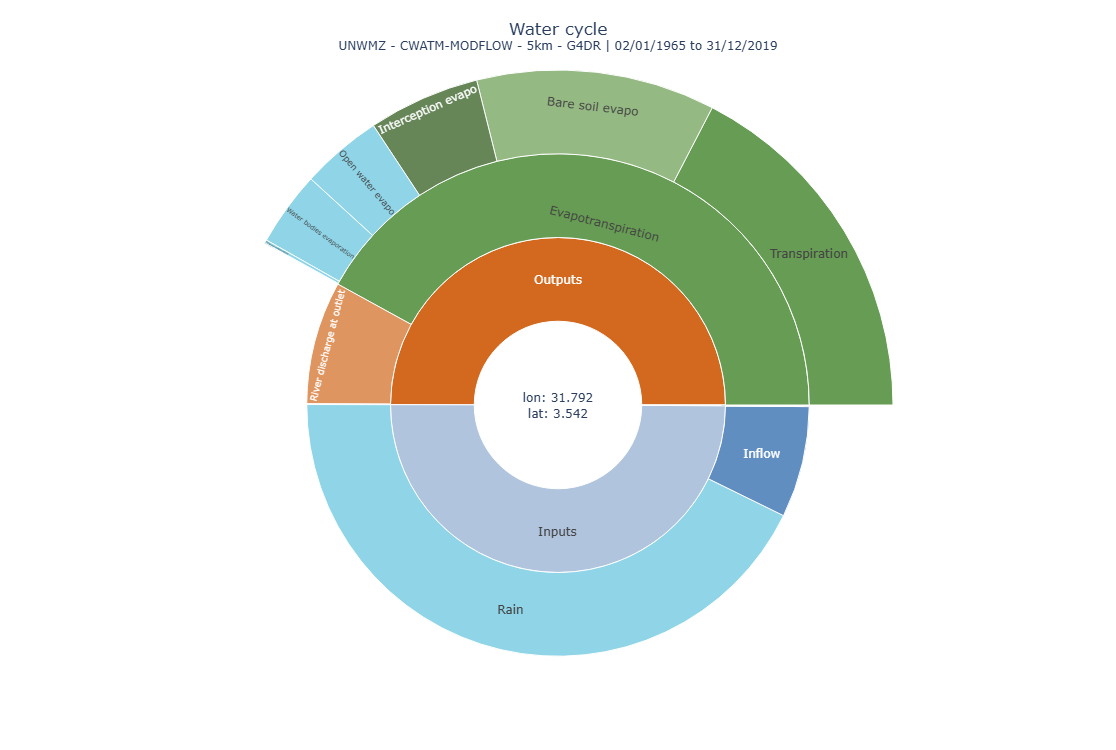

In [29]:
# cell no 06: overall sunburst (layout and colours as in the GUI analysis_watercycle.py)
storetext = "Storage (into)" if dstorage >= 0 else "Storage (out)"
center = f"lon: {lon:.3f}<br>lat: {lat:.3f}"
convert = 1e9   # m3 -> km3

# Storage wedge: one leaf with the total change (as in the GUI); storage taken out counts on the input side
labels = [center, "Inputs", "Outputs", "Balance", storetext]
parents = ["", center, center, center, center]
values = [0.0, total_input, total_output, abs(balance), abs(dstorage)]
for _, r in comp[comp.parent != "Storage"].iterrows():
    labels.append(r.label)
    parents.append(r.parent)
    values.append(abs(r.m3))
labels.append("")
parents.append(storetext)
values.append(abs(dstorage))
# branchvalues="total": plotly drops the children if they sum up to more than the parent
# (ET children are ~0.001 m3 bigger than the ET total by rounding) -> lift parents bottom-up
for par in ["Transpiration", "Evapotranspiration", "Outputs", "Inputs", storetext]:
    if par in labels:
        children = sum(v for v, p in zip(values, parents) if p == par)
        values[labels.index(par)] = max(values[labels.index(par)], children)
values[0] = sum(values[1:5])

label_color = {
    "Inputs": "#b0c4de", "Outputs": "#d2691e", "Balance": "white",
    "Rain": "#60C4DE", "Snow": "#8fd1d1", "Glacier": "#ADD8E6", "Inflow": "#1f5fa8",
    "River discharge at outlet": "#d2691e", "non-Irrigation consumption": "#d2691e",
    "Evapotranspiration": "#669C53", "Transpiration": "#669C53",
    "Bare soil evapo": "#699C4F", "Interception evapo": "#265312",
    "Open water evapo": "#60C4DE", "Snow evapo": "#8fd1d1", "Channel evaporation": "#60C4DE",
    "Water bodies evaporation": "#60C4DE", "Small lakes evaporation": "#60C4DE", "Irrigation losses": "#9b59b6",
    "Forest": "#265312", "Others": "#81c066", "Paddy": "#B66934", "non-Paddy": "#B66934",
}
colors = ["white" if p == "" else "#00CC96" if (l == storetext or p == storetext)
          else label_color.get(l, "#b0c4de" if p == "Inputs" else "#d2691e")
          for l, p in zip(labels, parents)]

out_side = {"Outputs", "Evapotranspiration", "Transpiration"}
custom = []
for i, (l, p, v) in enumerate(zip(labels, parents, values)):
    if i == 0:
        frac = ""
    elif p in out_side or l == "Outputs":
        frac = f"Percent of output: {v / total_output:.2%}" if total_output else ""
    elif p == "Inputs" or l == "Inputs":
        frac = f"Percent of input: {v / total_input:.2%}" if total_input else ""
    else:
        frac = f"Percent of input: {v / total_input:.3%}" if total_input else ""
    if l == "River discharge at outlet":
        unit = f"Discharge: {discharge_mean:.2f} m<sup>3</sup>/s"
    else:
        unit = f"mm/year: {v * to_mm / nyears:.1f} mm"
    custom.append([frac, unit, f"Volume: {v / convert:.4g} km<sup>3</sup>"])
custom[0][0] = f"Basin: {title}<br>Area: {area / 1e6:.0f} km<sup>2</sup><br>{period}"

hover = ["<b>%{label}</b><br>%{customdata[0]}<extra></extra>" if p == ""
         else "<b>%{label}</b><br>%{customdata[2]}<br>%{customdata[1]}<br>%{customdata[0]}<extra><b>%{parent}</b></extra>"
         for p in parents]

fig = go.Figure(go.Sunburst(labels=labels, parents=parents, values=values, branchvalues="total",
                            customdata=custom, hovertemplate=hover, marker=dict(colors=colors), maxdepth=4))
fig.update_layout(title=dict(text=f"Water cycle<br><sup>{title} | {period}</sup>", x=0.5),
                  width=750, height=750, margin=dict(l=10, r=10, t=70, b=10), hoverlabel=dict(align="left"))
figs["Water cycle"] = fig
fig.show()

## 2. Water cycle of the parts

Each balance sunburst: centre = part, 1st ring = **Inputs | Outputs | Storage (into) | Storage (out) | Balance error**,
2nd ring = the single terms. A storage which increased counts on the output side (into storage), a storage which decreased
on the input side (out of storage) - so both halves are equal (up to the balance error). A negative term (e.g. a negative
net recharge) is moved to the other side. Only the parts and terms of the options which are on (cell no 02) are drawn.

In [30]:
# cell no 07: definition of the parts: (label, column) for In, Out and storages
# a term is used if its column is in the csv / was derived in cell no 03 (= its option is on)
gwname = "Groundwater" + (" (MODFLOW + coupling)" if modflow else "")
PARTS = {
    "Total": dict(
        In=[("Rain", "Rain"), ("Rain on snow", "Rain_on_snow"), ("Snow", "Snow"), ("Glacier", "glacier"), ("Inflow", "inflowDay"), ("Fossil groundwater", "fossil"),
            ("Lateral groundwater flow", "gw_lateral"), ("Recharge moved by the grid", "gw_rechargeMoved"),
            ("Reservoir transfer in", "res_transferIn")],
        Out=[("Evapotranspiration", "ET_all"), ("Discharge", "Q_m3"), ("Non-irrigation consumption", "act_nonIrrConsumption"),
             ("Unmet lost", "unmet_lost"), ("Canal leakage lost", "leakage_lost"),
             ("Canal leakage outside the catchment", "canalLeakOutside"), ("Reservoir transfer out", "res_transferOut")],
        S=[("Snow cover", "SnowCover"), ("Interception", "sum_interceptStor"), ("Soil moisture", "sum_soil"),
           ("Seepage pond", "pond"), ("Groundwater", "storGroundwater"), ("MODFLOW buffer", "modflow_buffer"),
           ("Runoff concentration", "gridcell_storage"), ("Channels", "channelStorage"), ("Lakes/reservoirs", "lakeResStorage"),
           ("Small lakes", "smalllakeStorage"), ("Lake inflow in transit", "lakeInflowTransit")]),
    "Soil (+interception, pond)": dict(
        In=[("Rain", "Rain"), ("Snow melt", "SnowMelt"), ("Ice melt", "IceMelt"), ("Irrigation", "act_totalIrrConsumption"),
            ("Capillary rise from groundwater" + (" (MODFLOW)" if modflow else ""), "capGW"),
            ("Capillary rise from aquifer", "capAq")],
        Out=[("Transpiration", "sum_actTransTotal"), ("Bare soil evaporation", "sum_actBareSoilEvap"),
             ("Interception evaporation", "sum_interceptEvap"), ("Open water + pond evaporation", "sum_openWaterEvap"),
             ("Runoff", "landRunoff"), ("Percolation", "percolation")],
        S=[("Interception", "sum_interceptStor"), ("Soil moisture", "sum_soil"), ("Seepage pond", "pond")]),
    gwname: dict(
        In=[("Percolation", "percolation"), ("River leakage", "riverbedExchangeM"), ("Lake leakage", "lakebedExchangeM"),
            ("Canal leakage", "leakageIntoGw"), ("Lateral groundwater flow", "gw_lateral"),
            # MODFLOW: a ModFlow cell mixes the recharge of the CWatM cells it overlaps (0 over the whole mask)
            ("Recharge moved by the grid", "gw_rechargeMoved")],
        Out=[("Baseflow", "baseflow"), ("Capillary rise", "capGW"), ("Capillary rise from aquifer", "capAq"),
             ("Rejected recharge", "rejected_recharge_interflow"), ("Pumping", "gwAbs"),
             ("Exported recharge", "gwRechargeExported_day")],
        S=[("Aquifer", "storGroundwater"), ("MODFLOW buffer", "modflow_buffer")]),
    "Snow": dict(
        In=[("Snowfall", "Snow"), ("Rain on snow", "Rain_on_snow")], Out=[("Snow melt", "SnowMelt"), ("Ice melt", "IceMelt"), ("Snow evaporation", "snowEvap")],
        S=[("Snow cover", "SnowCover")]),
    "Lakes/reservoirs": dict(
        In=[("Lake inflow", "lakeResInflowM"), ("Transfer in", "res_transferIn")],
        Out=[("Lake outflow", "lakeResOutflowM"), ("Evaporation", "EvapWaterBodyM"), ("Abstraction", "act_bigLakeResAbst"),
             ("Canal leakage", "leakage"), ("Lake leakage", "lakebedExchangeM"), ("Transfer out", "res_transferOut")],
        S=[("Lakes/reservoirs", "lakeResStorage")]),
    # channels without the big lakes: lake outflow in, lake inflow out
    "Channels (+small lakes)": dict(
        In=[("Runoff", "runoff"), ("Glacier", "glacier"), ("Return flow", "returnFlow"), ("Lake outflow", "lakeResOutflowM"),
            ("Inflow", "inflowDay")],
        Out=[("Discharge", "Q_m3"), ("Channel evaporation", "EvapoChannel"), ("Small lake evaporation", "smallevapWaterBody"),
             ("Channel abstraction", "channelAbs"), ("River leakage", "riverbedExchangeM"), ("Lake inflow", "lakeResInflowM")],
        # lake inflow in transit: has left the channels (or an upstream lake), not yet in the lake (lake inflow lag)
        S=[("Channels", "channelStorage"), ("Small lakes", "smalllakeStorage"), ("Lake inflow in transit", "lakeInflowTransit")]),
    "Routing (channels + lakes)": dict(
        In=[("Runoff", "runoff"), ("Glacier", "glacier"), ("Return flow", "returnFlow"), ("Inflow", "inflowDay"),
            ("Reservoir transfer in", "res_transferIn")],
        Out=[("Discharge", "Q_m3"), ("Channel evaporation", "EvapoChannel"), ("Lake evaporation", "EvapWaterBodyM"),
             ("Small lake evaporation", "smallevapWaterBody"), ("Surface water abstraction", "act_SurfaceWaterAbstract"),
             ("Canal leakage", "leakage"), ("River leakage", "riverbedExchangeM"), ("Lake leakage", "lakebedExchangeM"),
             ("Reservoir transfer out", "res_transferOut")],
        S=[("Channels", "channelStorage"), ("Lakes/reservoirs", "lakeResStorage"), ("Small lakes", "smalllakeStorage"),
           ("Lake inflow in transit", "lakeInflowTransit")]),
    "Water demand": dict(
        In=[("Surface water", "act_SurfaceWaterAbstract"), ("Groundwater", "gwAbs"), ("Fossil groundwater", "fossil")],
        Out=[("Irrigation consumption", "act_totalIrrConsumption"), ("Non-irrigation consumption", "act_nonIrrConsumption"),
             ("Irrigation losses (ET)", "addtoevapotrans"), ("Return flow", "returnFlow"), ("Unmet lost", "unmet_lost")],
        S=[]),
}
# parts which need an option
NEEDS = {"Lakes/reservoirs": "includeWaterBodies", "Channels (+small lakes)": "includeRouting",
         "Routing (channels + lakes)": "includeRouting", "Water demand": "includeWaterDemand"}
parts = {k: v for k, v in PARTS.items() if on.get(NEEDS.get(k), True)}

# interception, the 3 soil layers and the soil of each land cover (WaterCycle columns since 2026-10-15; older csv: not drawn)
NEWPARTS = {
    "Interception": dict(
        In=[("Rain", "Rain")], Out=[("Interception evaporation", "sum_interceptEvap"), ("Throughfall", "sum_throughfall")],
        S=[("Interception", "sum_interceptStor")]),
    "Soil layer 1": dict(
        In=[("Infiltration", "sum_infiltration"), ("Capillary rise from layer 2", "sum_capRise2to1")],
        Out=[("Transpiration", "sum_ta1"), ("Bare soil evaporation", "sum_actBareSoilEvap"), ("Percolation to layer 2", "sum_perc1to2"),
             ("Infiltration excess to layer 2", "sum_excess1to2"), ("Capillary rise overflow to runoff", "sum_capOverflowRunoff")],
        S=[("Layer 1", "sum_w1")]),
    "Soil layer 2": dict(
        In=[("Percolation from layer 1", "sum_perc1to2"), ("Infiltration excess from layer 1", "sum_excess1to2"),
            ("Capillary rise from layer 3", "sum_capRise3to2"), ("Seepage pond overflow", "pond2soil2")],
        Out=[("Capillary rise to layer 1", "sum_capRise2to1"), ("Transpiration", "sum_ta2"), ("Percolation to layer 3", "sum_perc2to3")],
        S=[("Layer 2", "sum_w2")]),
    "Soil layer 3": dict(
        In=[("Percolation from layer 2", "sum_perc2to3"),
            ("Capillary rise from groundwater" + (" (MODFLOW)" if modflow else ""), "sum_capRiseFromGW"),
            ("Seepage pond overflow", "pond2soil3")],
        Out=[("Capillary rise to layer 2", "sum_capRise3to2"), ("Transpiration", "sum_ta3"), ("Percolation to groundwater", "sum_perc3toGW")],
        S=[("Layer 3", "sum_w3")]),
}
SOILLC = []
for cov, lab in [("forest", "forest"), ("grassland", "grassland"), ("irrPaddy", "paddy"), ("irrNonPaddy", "non-paddy")]:
    if cov + "_inWater" in df.columns and flux(cov + "_inWater") > 0.01:      # at least 0.01 mm over the period
        SOILLC.append("Soil " + lab)
        NEWPARTS["Soil " + lab] = dict(
            In=[("Throughfall + snow melt", cov + "_inWater"), ("Irrigation", cov + "_irrigation"),
                ("Capillary rise from groundwater", cov + "_capRise"), ("Seepage into the pond", cov + "_seepage")],
            Out=[("Transpiration", cov + "_transp"), ("Bare soil evaporation", cov + "_bareSoilEvap"),
                 ("Open water + pond evaporation", cov + "_openWaterEvap"), ("Direct runoff", cov + "_directRunoff"),
                 ("Percolation", cov + "_perc3toGW"), ("Preferential flow", cov + "_prefFlow")],
            S=[("Soil" + (" + paddy water" if cov == "irrPaddy" else "") + (" + pond" if on["modflow_seepage"] else ""),
                cov + "_soilStor")])
parts.update({k: v for k, v in NEWPARTS.items() if v["S"][0][1] in df.columns})

# runoff concentration (WaterBalance csv): direct runoff, interflow (incl. rejected recharge), baseflow, canal leakage
# -> runoff to the river; storage only with includeRunoffConcentration
if "sum_directRunoff" in df.columns:
    parts["Runoff concentration"] = dict(
        In=[("Direct runoff", "sum_directRunoff"), ("Interflow", "sum_interflow"), ("Baseflow", "baseflow"),
            ("Canal leakage", "leakageIntoRunoff")],
        Out=[("Runoff to the river", "runoff")],
        S=[("Runoff concentration", "gridcell_storage")])
# pySnowClim snow pack (WaterBalance csv): condensation and deposition are negative for a gain -> as gain inputs
if on["usepySnowClim"] and "snowSWE" in df.columns:
    df["condensationGain"] = -z("condensation")
    df["depositionGain"] = -z("deposition")
    parts["Snow pack (pySnowClim)"] = dict(
        In=[("Snowfall", "Snow"), ("Rain on snow", "Rain_on_snow"), ("Condensation", "condensationGain"),
            ("Deposition", "depositionGain")],
        Out=[("Melt water out of the pack", "SnowMelt"), ("Sublimation", "sublimation"),
             ("Evaporation of pack water", "snowwaterevaporation"), ("Snow reset", "snowReset")],
        S=[("Snow (SWE)", "snowSWE"), ("Pack water", "packwater")])
snowname = "Snow pack (pySnowClim)" if "Snow pack (pySnowClim)" in parts else "Snow"
# glacier (WaterBalance csv): precipitation on the glacier area in, melt and rain to the routing out; CWatM has no
# glacier storage (melt and rain come from an external glacier model) -> the difference is the implied glacier change
if on["includeGlaciers"] and "glacierAreaSnow" in df.columns:
    gl_in = z("glacierAreaSnow") + z("glacierAreaRain")
    gl_out = z("GlacierMelt") + z("GlacierRain")
    df["glacierImplied"] = (gl_in - gl_out).where(df.index > df.index[0], 0.).cumsum()
    parts["Glacier"] = dict(
        In=[("Snowfall on glacier", "glacierAreaSnow"), ("Rain on glacier", "glacierAreaRain")],
        Out=[("Glacier melt", "GlacierMelt"), ("Rain on glacier to the routing", "GlacierRain")],
        S=[("Glacier change (implied)", "glacierImplied")])
# lakes and reservoirs separately (WaterBalance csv): lakes = lake routine (type 1, 6), reservoirs = all other types
# (also not yet built: inflow = outflow); abstraction is booked on the cells around the water body
for wb, nm in [("lake", "Lakes"), ("res", "Reservoirs")]:
    if wb + "_storage" in df.columns:
        parts[nm] = dict(
            In=[("Inflow", wb + "_inflow"), ("Transfer in", wb + "_transferIn")],
            Out=[("Outflow", wb + "_outflow"), ("Evaporation", wb + "_evap"), ("Abstraction", wb + "_abstraction"),
                 ("Canal leakage", wb + "_leakage"), ("Lakebed leakage", wb + "_bedExchange"), ("Transfer out", wb + "_transferOut")],
            S=[(nm, wb + "_storage")])
# MODFLOW budget of each layer (WaterBalance csv): lateral = net flow from the cells of the same layer (inside the
# catchment it cancels -> flow across the border), flow between the layers, recharge and drains (layer 1), pumping
GWLAYERS = []
n = 1
while f"gwlayer{n}_storage" in df.columns:
    L = f"gwlayer{n}_"
    GWLAYERS.append(f"Aquifer layer {n}")
    parts[f"Aquifer layer {n}"] = dict(
        In=([("Recharge", "gwlayer1_recharge")] if n == 1 else []) + [
            ("Lateral inflow", L + "lateral"), ("From the layer above", L + "fromAbove"), ("From the layer below", L + "fromBelow")],
        Out=([("Drains (baseflow + capillary rise)", "gwlayer1_drain")] if n == 1 else []) + [("Pumping", L + "pumping")],
        S=[(f"Layer {n}", L + "storage")])
    n += 1
# demand vs supply, irrigation use and non-irrigation use (WaterBalance csv)
if "totalWaterDemand" in df.columns:
    # unmetDemand: not supplied with limitAbstraction = True, else fossil groundwater (part of the withdrawal)
    df["unmetNotSupplied"] = z("unmetDemand") if opts.get("limitAbstraction", False) else 0.
    parts["Demand vs supply"] = dict(
        In=[("Irrigation paddy demand", "irrPaddyDemand"), ("Irrigation non-paddy demand", "irrNonpaddyDemand"),
            ("Domestic demand", "domesticDemand"), ("Industry demand", "industryDemand"), ("Livestock demand", "livestockDemand")],
        Out=[("Irrigation withdrawal", "act_irrWithdrawal"), ("Domestic withdrawal", "act_domWithdrawal"),
             ("Industry withdrawal", "act_indWithdrawal"), ("Livestock withdrawal", "act_livWithdrawal"),
             ("Not supplied (unmet)", "unmetNotSupplied")],
        S=[])
    parts["Irrigation use"] = dict(
        In=[("Paddy withdrawal", "act_irrPaddyWithdrawal"), ("Non-paddy withdrawal", "act_irrNonpaddyWithdrawal")],
        Out=[("Paddy consumption", "act_paddyConsumption"), ("Non-paddy consumption", "act_nonpaddyConsumption"),
             ("Return flow", "returnflowIrr"), ("Losses to ET", "addtoevapotrans"), ("Lost (fossil water)", "unmet_lostirr")],
        S=[])
    # (with includeWastewater the collected wastewater is not in the csv -> does not close)
    parts["Non-irrigation use"] = dict(
        In=[("Domestic withdrawal", "act_domWithdrawal"), ("Industry withdrawal", "act_indWithdrawal"),
            ("Livestock withdrawal", "act_livWithdrawal")],
        Out=[("Domestic consumption", "act_domConsumption"), ("Industry consumption", "act_indConsumption"),
             ("Livestock consumption", "act_livConsumption"), ("Return flow", "returnflowNonIrr"),
             ("Lost (fossil water)", "unmet_lostNonirr"), ("Pit latrines (to groundwater)", "pitLatrinToGW")],
        S=[])
DEMANDPARTS = [n for n in ["Demand vs supply", "Irrigation use", "Non-irrigation use"] if n in parts]
# command areas: a reservoir can supply cells outside the catchment of the station -> Total / Lakes / Routing may not close
note_ca = on["using_reservoir_command_areas"] and station != int(stations["area km2"].idxmax())

# abstraction from lakes / reservoirs at the outlet (WaterBalance csv): the lake circles lose what is taken from the
# lake (incl. canal leakage), wherever the users are; Routing and Total: lake water for users outside the catchment
if "lakeResAbstOutlet" in df.columns:
    for name, pre in [("Lakes/reservoirs", None), ("Lakes", "lake"), ("Reservoirs", "res")]:
        if name in parts:
            old = {"act_bigLakeResAbst", "leakage"} if pre is None else {pre + "_abstraction", pre + "_leakage"}
            parts[name]["Out"] = [t for t in parts[name]["Out"] if t[1] not in old] + [
                ("Abstraction (taken from the lakes)", "lakeResAbstOutlet" if pre is None else pre + "_abstOutlet")]
    for name in ["Routing (channels + lakes)", "Total"]:
        if name in parts:
            parts[name]["Out"] = parts[name]["Out"] + [("Lake water for users outside the catchment", "lakeAbstOutside")]
# lift areas (WaterBalance csv): channel water taken in the catchment for users outside (< 0: taken outside for users
# of the catchment) - an output of the water demand (abstraction in, lift water of the users out) and of Total
if "liftOutside" in df.columns:
    for name in ["Water demand", "Total"]:
        if name in parts:
            parts[name]["Out"] = parts[name]["Out"] + [("Lift water for users outside the catchment", "liftOutside")]

# wastewater (includeWastewater, WaterBalance csv): sewer collection from the non-irrigation return flow and from
# urban runoff (sealed areas) -> treatment (storage) -> overflow / treated water to the river (in the return flow),
# to reservoirs, evaporation, export out of the model; reuse taken from the wastewater reservoirs
if "wwtSewerCollection" in df.columns:
    parts["Wastewater"] = dict(
        In=[("Sewer collection", "wwtSewerCollection")],
        Out=[("Overflow + treated to the river", "wwtOverflowOut"), ("Treated to reservoirs", "wwtSentToRes"),
             ("Evaporation", "wwtEvap"), ("Exported", "wwtSewerExported")],
        S=[("In treatment", "wwtInTreatment")])
    add = {"Total": dict(Out=[("Wastewater evaporation", "wwtEvap"), ("Wastewater exported", "wwtSewerExported")],
                         S=[("Wastewater in treatment", "wwtInTreatment")]),
           "Soil (+interception, pond)": dict(Out=[("Urban runoff to the sewer", "wwtUrbanLeakage")]),
           "Water demand": dict(Out=[("Collected to the sewer", "wwtSewerCollectedBySoruce")]),
           "Non-irrigation use": dict(Out=[("Collected to the sewer", "wwtSewerCollectedBySoruce")]),
           # reuse: part of the abstraction at the outlet (lakeResAbstOutlet, since 2026-10-16), else the users'
           "Lakes/reservoirs": dict(In=[("Treated wastewater", "wwtSentToRes")],
                                    Out=[] if "lakeResAbstOutlet" in df.columns else
                                    [("Wastewater reuse", "act_bigLakeResAbst_wwt")]),
           "Reservoirs": dict(In=[("Treated wastewater", "wwtSentToRes")],
                              Out=[] if "lakeResAbstOutlet" in df.columns else
                              [("Wastewater reuse", "act_bigLakeResAbst_wwt")]),
           "Routing (channels + lakes)": dict(In=[("Treated wastewater to reservoirs", "wwtSentToRes")])}
    for name, terms in add.items():
        if name in parts:
            for side, lst in terms.items():
                parts[name][side] = parts[name][side] + lst


def part_terms(p):
    # (side, label, value mm): side In / Out / S+ (into storage) / S- (out of storage); negative fluxes change side
    terms = []
    for side, other, lst in (("In", "Out", p["In"]), ("Out", "In", p["Out"])):
        for label, col in lst:
            if col not in df.columns:
                continue
            v = flux(col)
            terms.append((side, label, v) if v >= 0 else (other, label + " (neg.)", -v))
    for label, col in p["S"]:
        if col in df.columns:
            v = change(col)
            terms.append(("S+", label, v) if v >= 0 else ("S-", label, -v))
    return terms


# circles not drawn: option off, or all terms 0 over the period (e.g. no reservoirs / no irrigation in this catchment)
excluded = [[k, "option off: " + NEEDS[k]] for k in PARTS if k not in parts]
for k in [k for k in parts if k != "Total" and all(abs(v) < 1e-9 for _, _, v in part_terms(parts[k]))]:
    del parts[k]
    excluded.append([k, "all terms 0 over the period (not in this catchment)"])
GWLAYERS = [n for n in GWLAYERS if n in parts]
DEMANDPARTS = [n for n in DEMANDPARTS if n in parts]
SOILLC = [n for n in SOILLC if n in parts]


# Evapotranspiration composition (cell no 15): land and water bodies
ET = {"Land": [("Transpiration forest", "actTransTotal_forest"), ("Transpiration grassland", "actTransTotal_grasslands"),
               ("Transpiration paddy", "actTransTotal_paddy"), ("Transpiration non-paddy", "actTransTotal_nonpaddy"),
               ("Bare soil", "sum_actBareSoilEvap"), ("Interception", "sum_interceptEvap"),
               ("Open water + pond", "sum_openWaterEvap"), ("Snow", "snowEvap"), ("Irrigation losses", "addtoevapotrans")],
      "Water bodies": [("Lakes/reservoirs", "EvapWaterBodyM"), ("Small lakes", "smallevapWaterBody"), ("Channels", "EvapoChannel")]}


# potential vs actual ET (WaterBalance csv): actual land ET + deficit = potential ET of the land covers (incl.
# irrigation losses); actual transpiration + deficit = potential transpiration
ETPOT = "sum_totalPotET" in df.columns
if ETPOT:
    et_land = [(l, c) for l, c in ET["Land"] if not l.startswith("Transpiration ")]
    et_land.insert(0, ("Transpiration", "sum_actTransTotal"))
    etpot = {"Actual ET": [(l, flux(c)) for l, c in et_land],
             "Deficit": [("ET deficit", flux("sum_totalPotET") - flux("totalET"))]}
    trpot = {"Actual transpiration": [(l, flux(c)) for l, c in ET["Land"] if l.startswith("Transpiration ")],
             "Deficit": [("Transpiration deficit", flux("sum_potTranspiration") - flux("sum_actTransTotal"))]}


# Glacier (no storage): melt and rain on the glacier -> routing
GLACIER = [("Glacier melt", "GlacierMelt"), ("Rain on glacier", "GlacierRain")]
# water use: source x sector (sectorSourceAbstractionFractions), columns <source>_<sector>
SOURCES = [("Lake", "Lake"), ("Reservoir", "Res"), ("Channel", "Channel"), ("Groundwater", "GW"), ("Desalination", "Desal"),
           ("Lift area", "Lift"), ("Wastewater reuse", "wwt")]
SECTORS = ["Irrigation", "Domestic", "Industry", "Livestock"]
use = {(src, sec): flux(f"{c}_{sec}") for src, c in SOURCES for sec in SECTORS
       if on["sectorSourceAbstractionFractions"] and f"{c}_{sec}" in df.columns}
withdrawal = flux("act_irrWithdrawal") + flux("act_nonIrrWithdrawal")


def part_row(name, p):
    t = part_terms(p)
    s = {k: sum(v for side, _, v in t if side == k) for k in ("In", "Out", "S+", "S-")}
    return [name, "balance", s["In"], s["Out"], s["S+"] - s["S-"], s["In"] + s["S-"] - s["Out"] - s["S+"],
            ", ".join(l for l, c in p["In"] + p["Out"] + p["S"] if c in df.columns)]


# all circles in the order they are drawn
# balance: In / Out = fluxes, dS = storage change, error = In - Out - dS
# composition (ET): In = total ET, Out = sum of the parts, error = difference
# storage: In = storage decrease, Out = storage increase, dS = net change
rows = [["Water cycle (overall, GUI)", "balance", total_input * to_mm, total_output * to_mm, dstorage * to_mm, balance * to_mm,
         ", ".join(comp.loc[comp.parent.isin(["Inputs", "Outputs", "Storage"]), "label"])]]
for name in ["Total", "Interception", "Soil (+interception, pond)", "Soil layer 1", "Soil layer 2", "Soil layer 3"] + SOILLC + [
        gwname] + GWLAYERS + ["Runoff concentration"]:
    if name in parts:
        rows.append(part_row(name, parts[name]))
et_terms = [(l, c) for lst in ET.values() for l, c in lst if c in df.columns and flux(c) > 0]
et_tot, et_sum = flux("ET_all"), sum(flux(c) for _, c in et_terms)
rows.append(["Evapotranspiration", "composition", et_tot, et_sum, 0., et_tot - et_sum, ", ".join(l for l, _ in et_terms)])
if ETPOT:
    # potential: In = potential, Out = actual, dS = deficit (not a balance)
    for nm, pot, act in [("ET: potential vs actual (land)", "sum_totalPotET", "totalET"),
                         ("Transpiration: potential vs actual", "sum_potTranspiration", "sum_actTransTotal")]:
        rows.append([nm, "potential", flux(pot), flux(act), np.nan, np.nan,
                     f"deficit {flux(pot) - flux(act):.2f} mm = {100 * (1 - flux(act) / flux(pot)):.1f} % of the potential"])
st_terms = [(l, change(c)) for l, c in parts["Total"]["S"] if c in df.columns]
st_inc, st_dec = sum(v for _, v in st_terms if v > 0), -sum(v for _, v in st_terms if v < 0)
rows.append(["Storage change (increase vs decrease)", "storage", st_dec, st_inc, st_inc - st_dec, np.nan,
             ", ".join(f"{l} {v:+.2f}" for l, v in st_terms)])
if snowname in parts:
    rows.append(part_row(snowname, parts[snowname]))
if "Glacier" in parts:
    r = part_row("Glacier", parts["Glacier"])
    r[1] = "implied storage"
    rows.append(r)
elif on["includeGlaciers"]:
    gl = [(l, flux(c)) for l, c in GLACIER]
    rows.append(["Glacier", "composition", flux("glacier"), sum(v for _, v in gl), 0., flux("glacier") - sum(v for _, v in gl),
                 ", ".join(f"{l} {v:.2f}" for l, v in gl)])
for name in ["Lakes/reservoirs", "Lakes", "Reservoirs", "Channels (+small lakes)", "Routing (channels + lakes)",
             "Water demand"] + DEMANDPARTS + ["Wastewater"]:
    if name in parts:
        rows.append(part_row(name, parts[name]))
if use:
    rows.append(["Water use: source x sector", "composition", withdrawal, sum(use.values()), 0., withdrawal - sum(use.values()),
                 ", ".join(sorted({src for src, _ in use})) + " x " + ", ".join(SECTORS)])
summary = pd.DataFrame(rows, columns=["circle", "kind", "In mm", "Out mm", "dS mm", "balance error mm", "terms"]).set_index("circle")
summary.insert(5, "error / In", summary["balance error mm"] / summary["In mm"])
# 2nd list: circles without a balance error (not a balance) and circles not drawn
REASON = {"potential": "no balance: potential vs actual, the difference is the deficit (water stress), not an error",
          "storage": "no balance: storage change split into decrease (In) and increase (Out), dS = Out - In by definition",
          "implied storage": "no balance: CWatM has no glacier storage, the difference is the implied glacier change "
                             "(error 0 by definition)"}
nobal = summary["kind"].isin(list(REASON))
others = pd.DataFrame([[c, k, REASON[k], t] for c, k, t in zip(summary.index[nobal], summary["kind"][nobal], summary["terms"][nobal])]
                      + [[c, "not drawn", r, ""] for c, r in excluded],
                      columns=["circle", "kind", "why not in the 1st list", "info"]).set_index("circle")
summary = summary[~nobal]
# 1st list in mm per year (sums over the period / number of years), without the column kind (mostly balance);
# error / In is the same for the period and per year
summary = pd.concat([(summary[["In mm", "Out mm", "dS mm", "balance error mm"]] / nyears).set_axis(
    ["In mm/yr", "Out mm/yr", "dS mm/yr", "error mm/yr"], axis=1), summary[["error / In", "terms"]]], axis=1)
print("interception / soil layers / soil per land cover:", "in the csv" if "Soil layer 1" in parts else "not in this csv (WaterCycle csv: use OUT_TSS_AreaSum_Daily = WaterBalance)")
print("In / Out: balance = fluxes; composition = total / sum of the parts (Evapotranspiration, Glacier, Water use: "
      "withdrawal / sum of source x sector); Storage = decrease / increase")
if note_ca:
    print("using_reservoir_command_areas: Total, Lakes and Routing of a sub-catchment may not close")
# |error / In| above the threshold tol (cell no 01): red
def red(v):
    return "color: #d62728; font-weight: bold" if pd.notna(v) and abs(v) > tol else ""


sty = summary.style.format({"In mm/yr": "{:.2f}", "Out mm/yr": "{:.2f}", "dS mm/yr": "{:.3f}", "error mm/yr": "{:.5f}",
                            "error / In": "{:.1e}"})
sty = (sty.map if hasattr(sty, "map") else sty.applymap)(red, subset=["error / In"])
print(f"values in mm per year (period {period}, {nyears:.2f} years)")
print(f"threshold |error / In| = {tol:g}: {int((summary['error / In'].abs() > tol).sum())} circle(s) above it (red)")
display(sty)
print("circles not in the list above:")
with pd.option_context("display.max_colwidth", 200):
    display(others)

interception / soil layers / soil per land cover: in the csv
In / Out: balance = fluxes; composition = total / sum of the parts (Evapotranspiration, Glacier, Water use: withdrawal / sum of source x sector); Storage = decrease / increase
values in mm per year (period 02/01/1965 to 31/12/2019, 55.00 years)
threshold |error / In| = 0.001: 2 circle(s) above it (red)


,In mm/yr,Out mm/yr,dS mm/yr,error mm/yr,error / In,terms
circle,,,,,,
"Water cycle (overall, GUI)",1421.93,1424.00,-2.075,0.00760,5.3e-06,"Rain, Inflow, Lateral groundwater flow, Recharge moved by the grid, River discharge at outlet, non-Irrigation consumption, Evapotranspiration, Interception storage, Channel storage, Lake/reservoir storage, Small lake storage, Runoff concentration storage, Groundwater storage, MODFLOW buffer, Soil storage, Seepage pond"
Total,1422.75,1424.82,-2.075,0.00760,5.3e-06,"Rain, Snow, Inflow, Lateral groundwater flow, Recharge moved by the grid, Evapotranspiration, Discharge, Non-irrigation consumption, Unmet lost, Snow cover, Interception, Soil moisture, Seepage pond, Groundwater, MODFLOW buffer, Runoff concentration, Channels, Lakes/reservoirs, Small lakes"
Interception,1218.82,1218.82,-0.000,-0.00000,-2.9e-09,"Rain, Interception evaporation, Throughfall, Interception"
"Soil (+interception, pond)",1347.11,1348.19,-1.080,-0.00137,-1.0e-06,"Rain, Snow melt, Ice melt, Irrigation, Capillary rise from groundwater (MODFLOW), Capillary rise from aquifer, Transpiration, Bare soil evaporation, Interception evaporation, Open water + pond evaporation, Runoff, Percolation, Interception, Soil moisture, Seepage pond"
Soil layer 1,857.81,857.95,-0.140,-0.00002,-2.6e-08,"Infiltration, Capillary rise from layer 2, Transpiration, Bare soil evaporation, Percolation to layer 2, Infiltration excess to layer 2, Capillary rise overflow to runoff, Layer 1"
Soil layer 2,525.26,525.32,-0.057,-0.00324,-6.2e-06,"Percolation from layer 1, Infiltration excess from layer 1, Capillary rise from layer 3, Seepage pond overflow, Capillary rise to layer 1, Transpiration, Percolation to layer 3, Layer 2"
Soil layer 3,161.38,162.30,-0.920,0.00190,1.2e-05,"Percolation from layer 2, Capillary rise from groundwater (MODFLOW), Seepage pond overflow, Capillary rise to layer 2, Transpiration, Percolation to groundwater, Layer 3"
Soil forest,762.35,762.42,-0.070,0.00061,8.0e-07,"Throughfall + snow melt, Irrigation, Capillary rise from groundwater, Seepage into the pond, Transpiration, Bare soil evaporation, Open water + pond evaporation, Direct runoff, Percolation, Preferential flow, Soil + pond"
Soil grassland,352.00,353.01,-1.015,0.00254,7.2e-06,"Throughfall + snow melt, Irrigation, Capillary rise from groundwater, Seepage into the pond, Transpiration, Bare soil evaporation, Open water + pond evaporation, Direct runoff, Percolation, Preferential flow, Soil + pond"


circles not in the list above:


,kind,why not in the 1st list,info
circle,,,
ET: potential vs actual (land),potential,"no balance: potential vs actual, the difference is the deficit (water stress), not an error",deficit 59965.25 mm = 50.0 % of the potential
Transpiration: potential vs actual,potential,"no balance: potential vs actual, the difference is the deficit (water stress), not an error",deficit 56227.19 mm = 67.4 % of the potential
Storage change (increase vs decrease),storage,"no balance: storage change split into decrease (In) and increase (Out), dS = Out - In by definition","Snow cover +0.00, Interception -0.00, Soil moisture -61.43, Seepage pond +2.05, Groundwater +8.26, MODFLOW buffer -0.01, Runoff concentration -8.51, Channels +41.78, Lakes/reservoirs -96.12, Small..."
Snow,not drawn,all terms 0 over the period (not in this catchment),
Reservoirs,not drawn,all terms 0 over the period (not in this catchment),


In [31]:
# cell no 08: sunburst function
COL = {"In": "#6fa8dc", "Out": "#d2691e", "S+": "#00CC96", "S-": "#7fd8b5", "Balance": "#ffffff"}
TERMCOL = {"Rain": "#60C4DE", "Snow": "#8fd1d1", "Snowfall": "#8fd1d1", "Snow melt": "#8fd1d1", "Inflow": "#1f5fa8",
           "Glacier": "#ADD8E6", "Discharge": "#a0522d", "Evapotranspiration": "#669C53", "Transpiration": "#669C53",
           "Percolation": "#b08d57", "Baseflow": "#8b6f47", "Capillary rise": "#c9a26b",
           "Capillary rise from groundwater": "#c9a26b", "Capillary rise from groundwater (MODFLOW)": "#c9a26b",
           "Runoff": "#4a90c2", "Pumping": "#9b59b6", "Irrigation": "#9b59b6"}
RING1 = {"In": "Inputs", "Out": "Outputs", "S+": "Storage (into)", "S-": "Storage (out)"}


def sunburst(name, terms, centre_note="", store=True):
    total_in = sum(v for side, _, v in terms if side in ("In", "S-"))
    total_out = sum(v for side, _, v in terms if side in ("Out", "S+"))
    err = total_in - total_out
    centre = f"<b>{name}</b>"
    labels, parents, values, colors, hover = [centre], [""], [0.], ["#ffffff"], [""]
    ids = [centre]
    for side in ("In", "S-", "Out", "S+"):
        kids = [(l, v) for s, l, v in terms if s == side and v > min_share * max(total_in, 1e-12)]
        sv = sum(v for s, _, v in terms if s == side)
        if sv <= 0:
            continue
        sid = f"{name}/{side}"
        ids.append(sid); labels.append(RING1[side]); parents.append(centre); values.append(sv)
        colors.append(COL[side]); hover.append(f"{sv:.2f} mm<br>{sv / nyears:.1f} mm/yr<br>{100 * sv / total_in:.2f} % of inputs")
        rest = sv - sum(v for _, v in kids)
        if rest > 0 and kids:
            kids.append(("other (small)", rest))
        for l, v in kids:
            ids.append(f"{sid}/{l}"); labels.append(l); parents.append(sid); values.append(v)
            colors.append(TERMCOL.get(l.replace(" (neg.)", ""), COL[side]))
            hover.append(f"{v:.3f} mm<br>{v / nyears:.1f} mm/yr<br>{100 * v / total_in:.2f} % of inputs")
    if abs(err) > 0:
        ids.append(f"{name}/err"); labels.append("Balance error"); parents.append(centre); values.append(abs(err))
        colors.append(COL["Balance"]); hover.append(f"{err:+.4f} mm ({err / total_in:+.1e} of inputs)")
    values[0] = sum(v for v, p in zip(values, parents) if p == centre)
    hover[0] = f"inputs {total_in:.2f} mm ({total_in / nyears:.0f} mm/yr)<br>balance error {err:+.4f} mm{centre_note}"
    fig = go.Figure(go.Sunburst(ids=ids, labels=labels, parents=parents, values=values, branchvalues="total",
                                marker=dict(colors=colors, line=dict(color="#888", width=0.5)), customdata=hover,
                                hovertemplate="<b>%{label}</b><br>%{customdata}<extra></extra>", insidetextorientation="radial"))
    fig.update_layout(title=dict(text=f"{name}<br><sup>{title} | {area / 1e6:.0f} km2 | {period}</sup>", x=0.5),
                      width=620, height=620, margin=dict(l=10, r=10, t=80, b=10))
    if store:
        figs[name] = fig
    return fig


def composition(name, groups, colors_grp, unit_total=None):
    # composition sunburst (not a balance): centre = total, 1st ring = groups, 2nd ring = parts; groups: {group: [(label, mm)]}
    total = sum(v for lst in groups.values() for _, v in lst)
    centre = f"<b>{name}</b>"
    ids, labels, parents, values = [centre], [centre], [""], [total]
    colors, hover = ["#ffffff"], [f"{total:.2f} mm, {total / nyears:.1f} mm/yr" + (f"<br>{unit_total}" if unit_total else "")]
    for grp, lst in groups.items():
        lst = [(l, v) for l, v in lst if v > 0]
        gv = sum(v for _, v in lst)
        if gv <= 0:
            continue
        ids.append(f"{name}/{grp}"); labels.append(grp); parents.append(centre); values.append(gv)
        colors.append(colors_grp.get(grp, "#b0c4de")); hover.append(f"{gv:.3f} mm, {gv / nyears:.1f} mm/yr, {100 * gv / total:.1f} %")
        for l, v in lst:
            ids.append(f"{name}/{grp}/{l}"); labels.append(l); parents.append(f"{name}/{grp}"); values.append(v)
            colors.append(colors_grp.get(l, colors_grp.get(grp, "#b0c4de")))
            hover.append(f"{v:.3f} mm, {v / nyears:.2f} mm/yr, {100 * v / total:.1f} %")
    values[0] = sum(v for v, p in zip(values, parents) if p == centre)
    compos[name] = groups
    fig = go.Figure(go.Sunburst(ids=ids, labels=labels, parents=parents, values=values, branchvalues="total",
                                marker=dict(colors=colors, line=dict(color="#888", width=0.5)), customdata=hover,
                                hovertemplate="<b>%{label}</b><br>%{customdata}<extra></extra>", insidetextorientation="radial"))
    fig.update_layout(title=dict(text=f"{name}<br><sup>{title} | {area / 1e6:.0f} km2 | {period}</sup>", x=0.5),
                      width=620, height=620, margin=dict(l=10, r=10, t=80, b=10))
    return fig


compos = {}      # composition circles (for the table of cell no 23)


def side_by_side(flist, key):
    # similar sunbursts next to each other in one figure
    n = len(flist)
    fig = go.Figure()
    ann = []
    for i, f in enumerate(flist):
        tr = f.data[0]
        tr.domain = dict(x=[i / n + 0.01, (i + 1) / n - 0.01], y=[0., 0.92])
        fig.add_trace(tr)
        ann.append(dict(text=f"<b>{f.layout.title.text.split('<br>')[0]}</b>", x=(i + 0.5) / n, y=1.0, xref="paper",
                        yref="paper", showarrow=False, font=dict(size=14)))
    fig.update_layout(title=dict(text=f"{key}<br><sup>{title} | {area / 1e6:.0f} km2 | {period}</sup>", x=0.5),
                      annotations=ann, width=520 * n, height=600, margin=dict(l=10, r=10, t=100, b=10))
    figs[key] = fig
    return fig

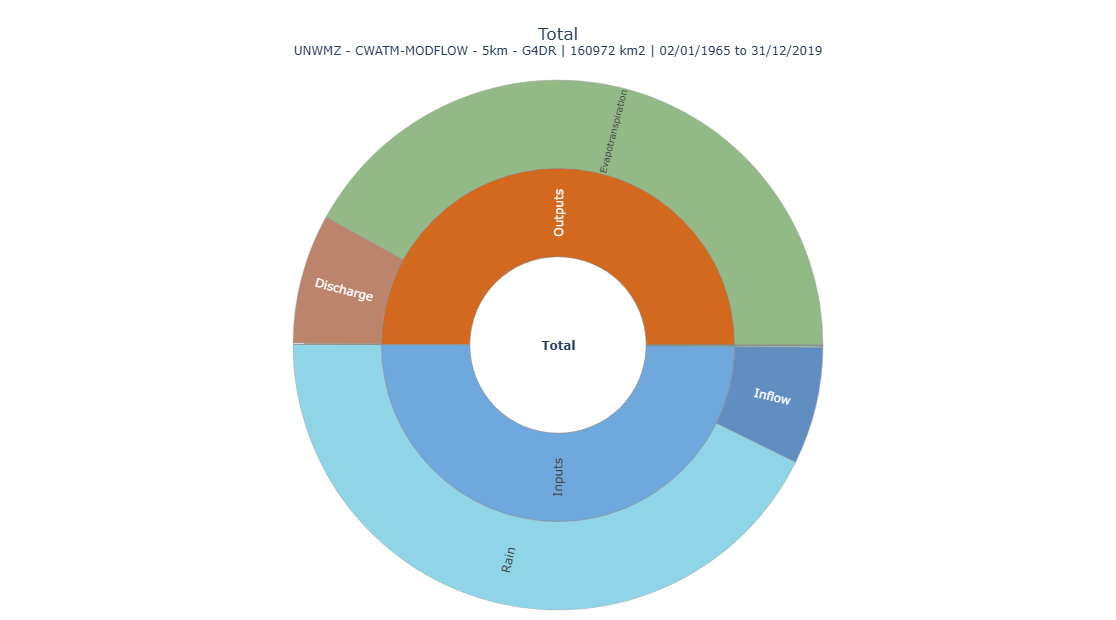

In [32]:
# cell no 09: Total water cycle (with inflow and MODFLOW buffer if on)
name = "Total"
sunburst(name, part_terms(parts[name])).show()

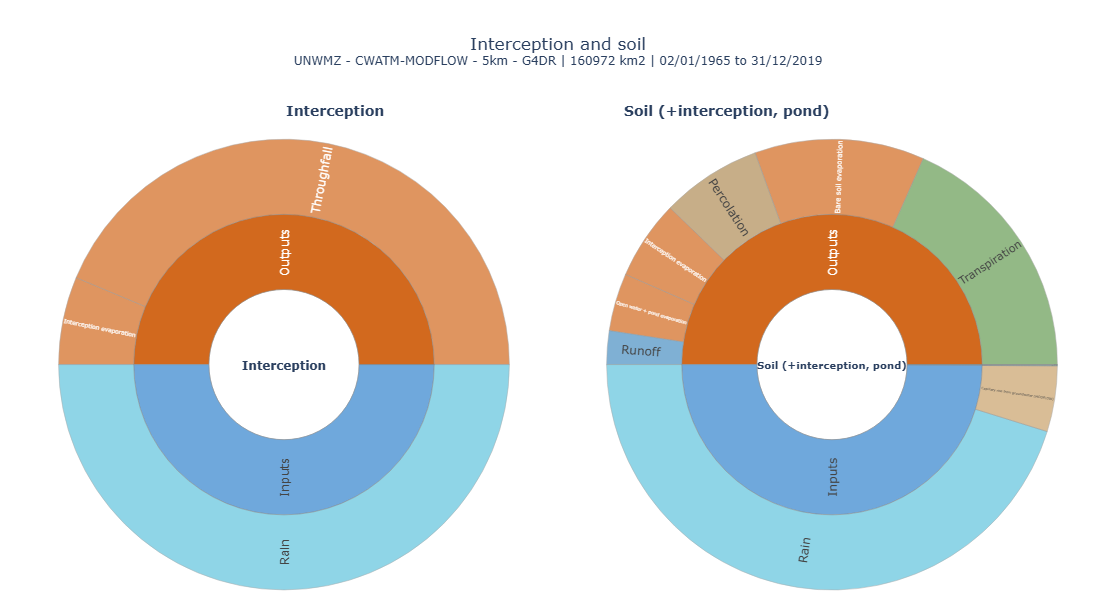

In [33]:
# cell no 10: Interception and Soil (+ interception and seepage pond) next to each other
names = [n for n in ["Interception", "Soil (+interception, pond)"] if n in parts]
side_by_side([sunburst(n, part_terms(parts[n]), store=False) for n in names], "Interception and soil").show()

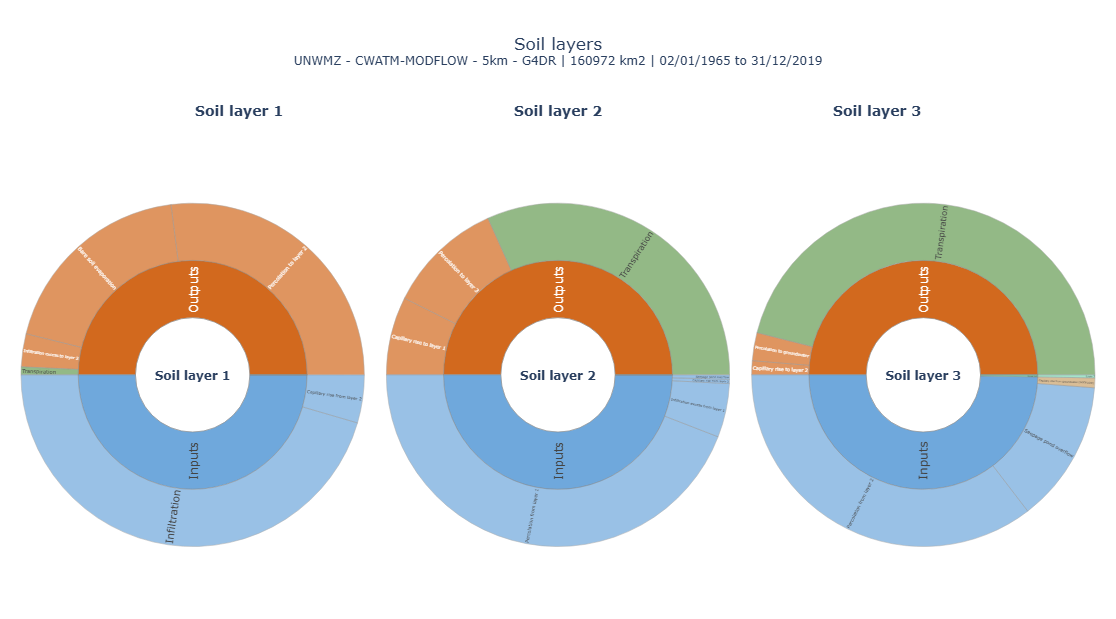

In [34]:
# cell no 11: the 3 soil layers next to each other (fluxes between the layers: percolation, infiltration excess,
# capillary rise; layer 3: capillary rise from groundwater, percolation to groundwater)
names = [n for n in ["Soil layer 1", "Soil layer 2", "Soil layer 3"] if n in parts]
if names:
    side_by_side([sunburst(n, part_terms(parts[n]), store=False) for n in names], "Soil layers").show()
else:
    print("soil layers: not in this csv (WaterCycle csv: use WaterBalance)")

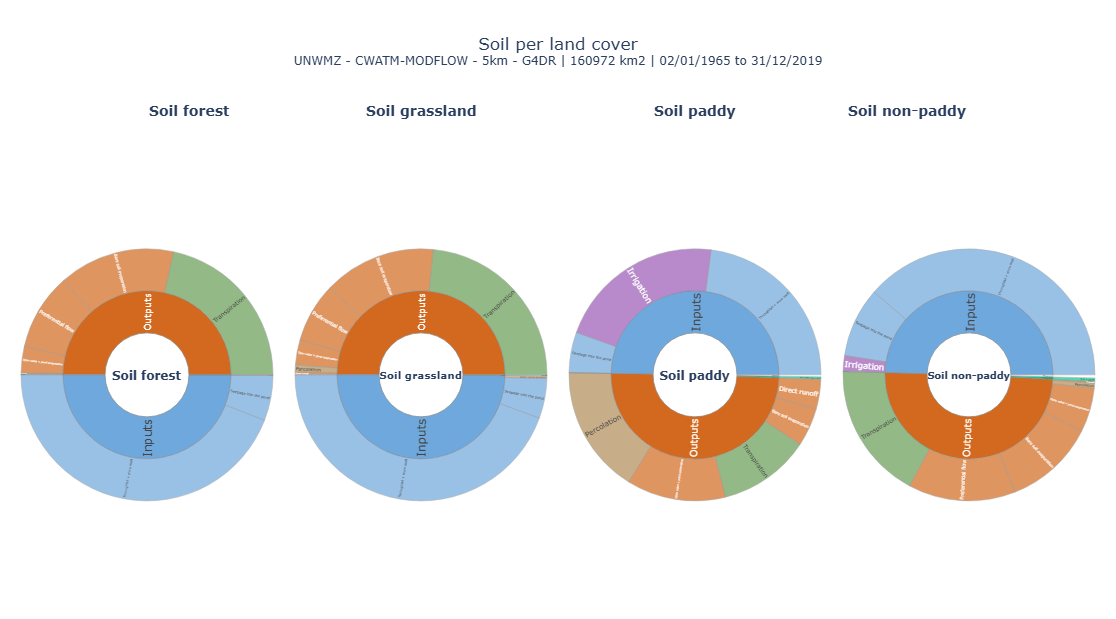

In [35]:
# cell no 12: soil of each land cover next to each other (depths over the whole cell: weighted by the land cover fraction)
if SOILLC:
    side_by_side([sunburst(n, part_terms(parts[n]), store=False) for n in SOILLC], "Soil per land cover").show()
else:
    print("soil per land cover: not in this csv (WaterCycle csv: use WaterBalance)")

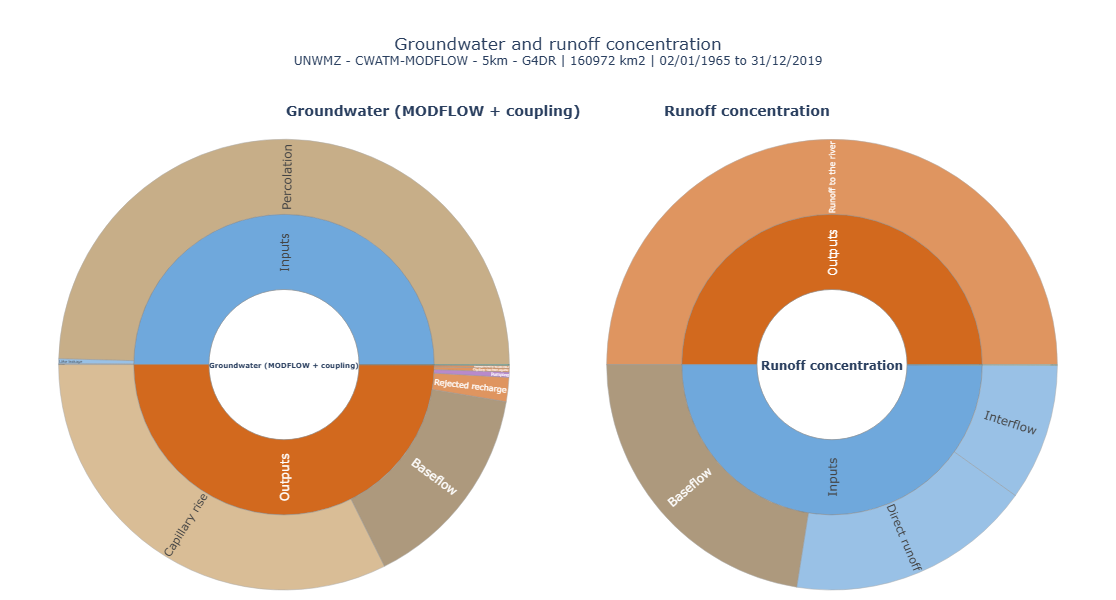

In [36]:
# cell no 13: Groundwater (with MODFLOW: aquifer + coupling buffer) and runoff concentration (WaterBalance csv:
# direct runoff, interflow, baseflow, canal leakage -> runoff to the river) next to each other
names = [n for n in [gwname, "Runoff concentration"] if n in parts]
side_by_side([sunburst(n, part_terms(parts[n]), store=False) for n in names], "Groundwater and runoff concentration").show()
if "Runoff concentration" not in parts:
    print("runoff concentration: not in this csv (WaterCycle csv: use WaterBalance)")

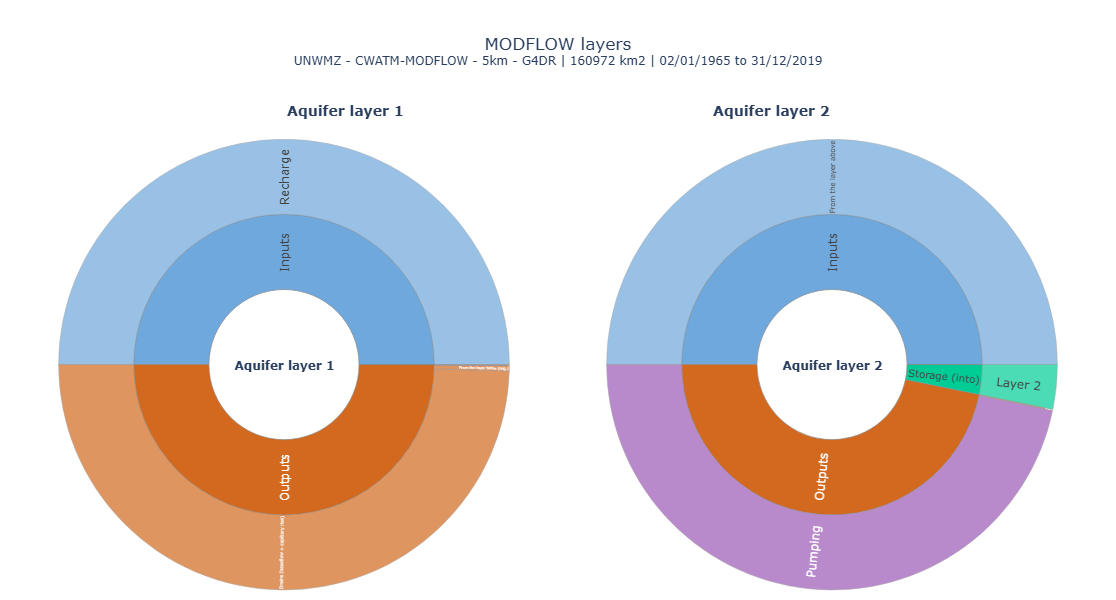

lateral groundwater flow into the catchment (all layers): -2.2856 mm


In [37]:
# cell no 14: MODFLOW budget of each aquifer layer next to each other (WaterBalance csv): lateral = net flow from
# the cells of the same layer outside the catchment, flow between the layers, recharge and drains in layer 1, pumping
if GWLAYERS:
    side_by_side([sunburst(n, part_terms(parts[n]), store=False) for n in GWLAYERS], "MODFLOW layers").show()
    print(f"lateral groundwater flow into the catchment (all layers): {flux('gw_lateral'):+.4f} mm")
else:
    print("MODFLOW layers: no MODFLOW or not in this csv (WaterCycle csv: use WaterBalance)")

ET total 65837.26 mm (1197 mm/yr), sum of the parts 65837.26 mm


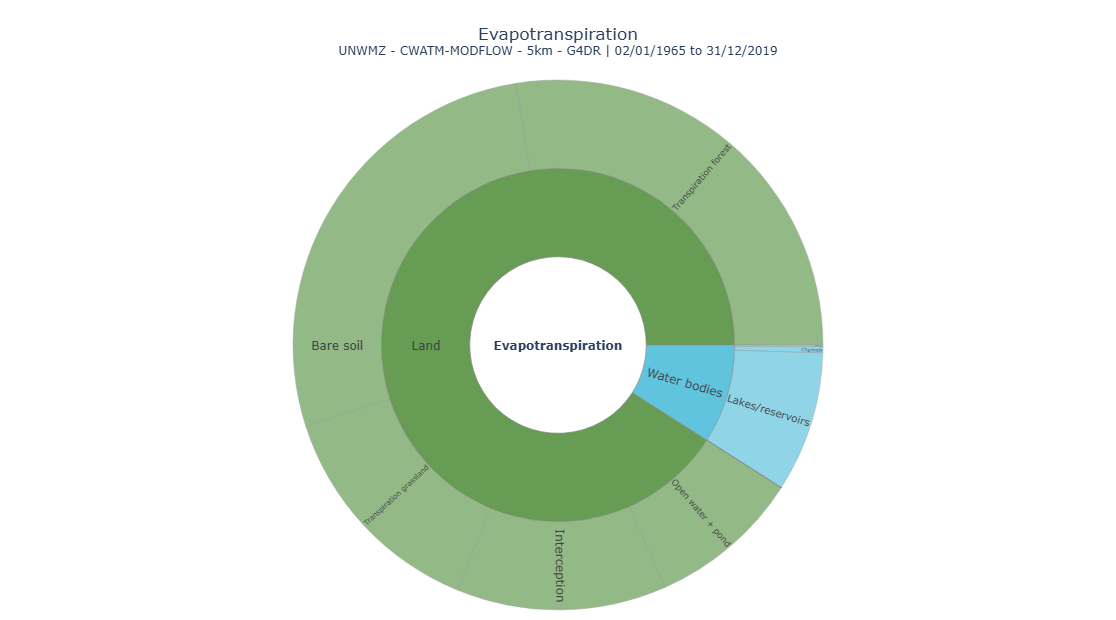

In [38]:
# cell no 15: Evapotranspiration - composition (not a balance): land and water bodies
# ET: terms defined in cell no 07
ETCOL = {"Land": "#669C53", "Water bodies": "#60C4DE"}
etsum = flux("ET_all")
centre = "<b>Evapotranspiration</b>"
ids, labels, parents, values, colors, hover = [centre], [centre], [""], [etsum], ["#ffffff"], [f"{etsum:.1f} mm, {etsum / nyears:.0f} mm/yr"]
for grp, lst in ET.items():
    vals = [(l, flux(c)) for l, c in lst if c in df.columns and flux(c) > 0]
    gv = sum(v for _, v in vals)
    if gv <= 0:
        continue
    ids.append(grp); labels.append(grp); parents.append(centre); values.append(gv); colors.append(ETCOL[grp])
    hover.append(f"{gv:.2f} mm, {gv / nyears:.0f} mm/yr, {100 * gv / etsum:.1f} %")
    for l, v in vals:
        ids.append(f"{grp}/{l}"); labels.append(l); parents.append(grp); values.append(v); colors.append(ETCOL[grp])
        hover.append(f"{v:.2f} mm, {v / nyears:.1f} mm/yr, {100 * v / etsum:.1f} %")
values[0] = sum(v for v, p in zip(values, parents) if p == centre)
# transpiration of the land covers + rest = sum_actTransTotal (check)
print(f"ET total {etsum:.2f} mm ({etsum / nyears:.0f} mm/yr), sum of the parts {values[0]:.2f} mm")
fig = go.Figure(go.Sunburst(ids=ids, labels=labels, parents=parents, values=values, branchvalues="total",
                            marker=dict(colors=colors, line=dict(color="#888", width=0.5)), customdata=hover,
                            hovertemplate="<b>%{label}</b><br>%{customdata}<extra></extra>", insidetextorientation="radial"))
fig.update_layout(title=dict(text=f"Evapotranspiration<br><sup>{title} | {period}</sup>", x=0.5), width=620, height=620,
                  margin=dict(l=10, r=10, t=80, b=10))
figs["Evapotranspiration"] = fig
fig.show()

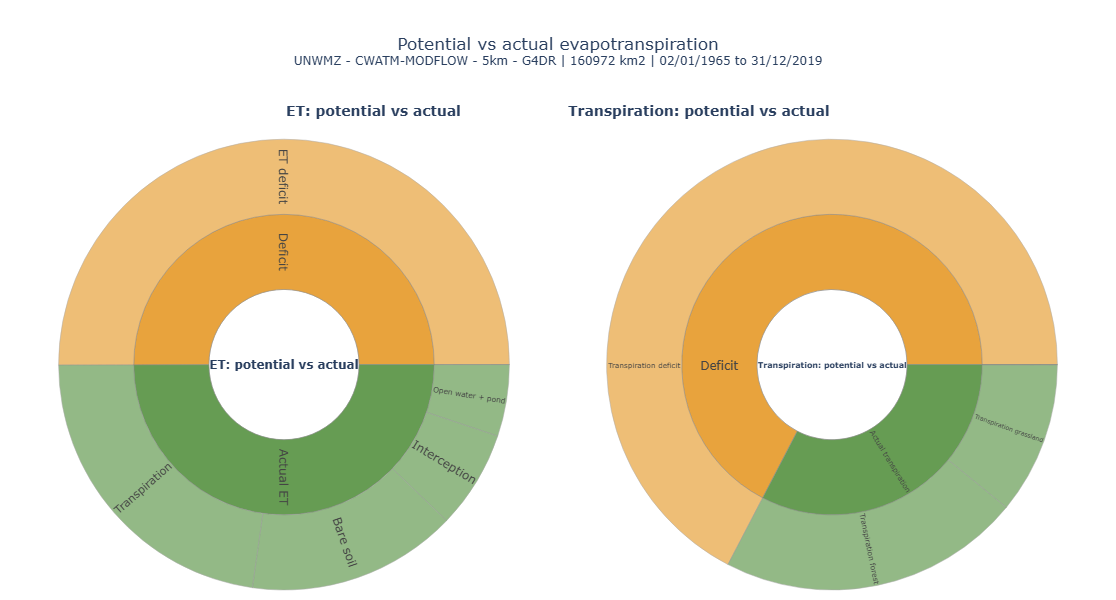

       ETRef     EWRef  potential ET  actual ET (land)  potential transp.  \
mm  81092.26  89862.48     119853.91          59888.65           83470.36   

    actual transp.  
mm        27243.17  


In [39]:
# cell no 16: potential vs actual: ET of the land (potential ET of the land covers incl. irrigation losses) and
# transpiration (potential after interception evaporation) - the deficit is the water stress
if ETPOT:
    POTCOL = {"Actual ET": "#669C53", "Actual transpiration": "#669C53", "Deficit": "#e8a33d", "ET deficit": "#e8a33d",
              "Transpiration deficit": "#e8a33d"}
    side_by_side([composition("ET: potential vs actual", etpot, POTCOL,
                              unit_total=f"potential ET; reference ET (crops) {flux('ETRef'):.1f} mm"),
                  composition("Transpiration: potential vs actual", trpot, POTCOL, unit_total="potential transpiration")],
                 "Potential vs actual evapotranspiration").show()
    print(pd.DataFrame([[flux("ETRef"), flux("EWRef"), flux("sum_totalPotET"), flux("totalET"), flux("sum_potTranspiration"),
                         flux("sum_actTransTotal")]], index=["mm"],
                       columns=["ETRef", "EWRef", "potential ET", "actual ET (land)", "potential transp.", "actual transp."]).round(2))
else:
    print("potential ET: not in this csv (WaterCycle csv: use WaterBalance)")

storage increase 52.09 mm, decrease 166.21 mm, net -114.12 mm


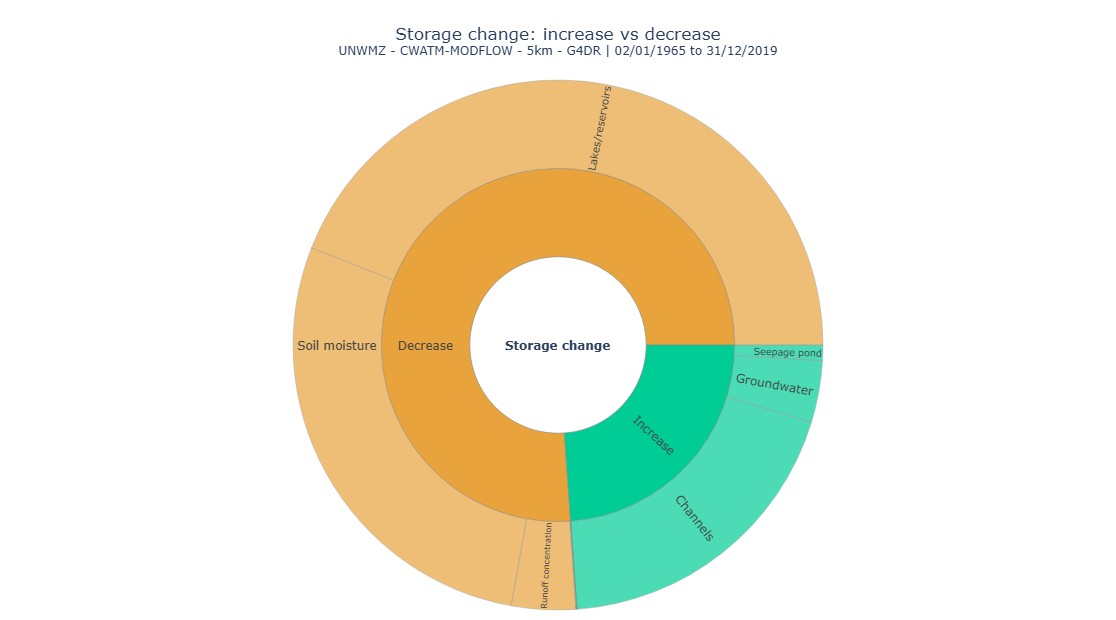

In [40]:
# cell no 17: Storage change - increase against decrease (all storages of the catchment)
terms = [(side, l, v) for side, l, v in part_terms(parts["Total"]) if side in ("S+", "S-")]
inc = sum(v for s, _, v in terms if s == "S+")
dec = sum(v for s, _, v in terms if s == "S-")
centre = "<b>Storage change</b>"
ids, labels, parents, values, colors, hover = [centre], [centre], [""], [inc + dec], ["#ffffff"], \
    [f"net {inc - dec:+.2f} mm ({(inc - dec) / nyears:+.0f} mm/yr)"]
for side, name_, col in (("S+", "Increase", "#00CC96"), ("S-", "Decrease", "#e8a33d")):
    sv = inc if side == "S+" else dec
    if sv <= 0:
        continue
    ids.append(name_); labels.append(name_); parents.append(centre); values.append(sv); colors.append(col)
    hover.append(f"{sv:.2f} mm")
    for s, l, v in terms:
        if s == side and v > 0:
            ids.append(f"{name_}/{l}"); labels.append(l); parents.append(name_); values.append(v); colors.append(col)
            hover.append(f"{'+' if side == 'S+' else '-'}{v:.3f} mm")
values[0] = sum(v for v, p in zip(values, parents) if p == centre)
print(f"storage increase {inc:.2f} mm, decrease {dec:.2f} mm, net {inc - dec:+.2f} mm")
fig = go.Figure(go.Sunburst(ids=ids, labels=labels, parents=parents, values=values, branchvalues="total",
                            marker=dict(colors=colors, line=dict(color="#888", width=0.5)), customdata=hover,
                            hovertemplate="<b>%{label}</b><br>%{customdata}<extra></extra>", insidetextorientation="radial"))
fig.update_layout(title=dict(text=f"Storage change: increase vs decrease<br><sup>{title} | {period}</sup>", x=0.5),
                  width=620, height=620, margin=dict(l=10, r=10, t=80, b=10))
figs["Storage change"] = fig
fig.show()

In [41]:
# cell no 18: Snow (pySnowClim: snow pack with rain on snow, sublimation, ...) and Glacier (only with includeGlaciers;
# WaterBalance csv: with the precipitation on the glacier area, no glacier storage in CWatM -> implied change)
flist = [sunburst(snowname, part_terms(parts[snowname]), store=False)] if snowname in parts else []
if snowname != "Snow":
    print(f"pySnowClim inside the pack: refrozen {flux('refrozen'):.2f} mm (pack water -> SWE), "
          f"melt {flux('snowmelt1'):.2f} mm (SWE -> pack water)")
if "Glacier" in parts:
    # balance with the precipitation on the glacier area; the storage is the implied glacier change (not simulated)
    flist.append(sunburst("Glacier", part_terms(parts["Glacier"]), store=False))
    print(f"glacier: implied change {change('glacierImplied'):+.2f} mm over the catchment "
          f"(precipitation on the glacier area - melt - rain to the routing; CWatM has no glacier storage)")
elif on["includeGlaciers"]:
    flist.append(composition("Glacier", {"Into the routing": [(l, flux(c)) for l, c in GLACIER]},
                              {"Into the routing": "#ADD8E6", "Rain on glacier": "#60C4DE"},
                              unit_total=f"glacier area {z('areaGlacier').iloc[-1] / 1e6:.1f} km2" if "areaGlacier" in df.columns else None))
else:
    print("Glacier: includeGlaciers off -> not drawn")
if flist:
    side_by_side(flist, "Snow and glacier").show()

Glacier: includeGlaciers off -> not drawn


not drawn (see the 2nd list of cell no 07): -


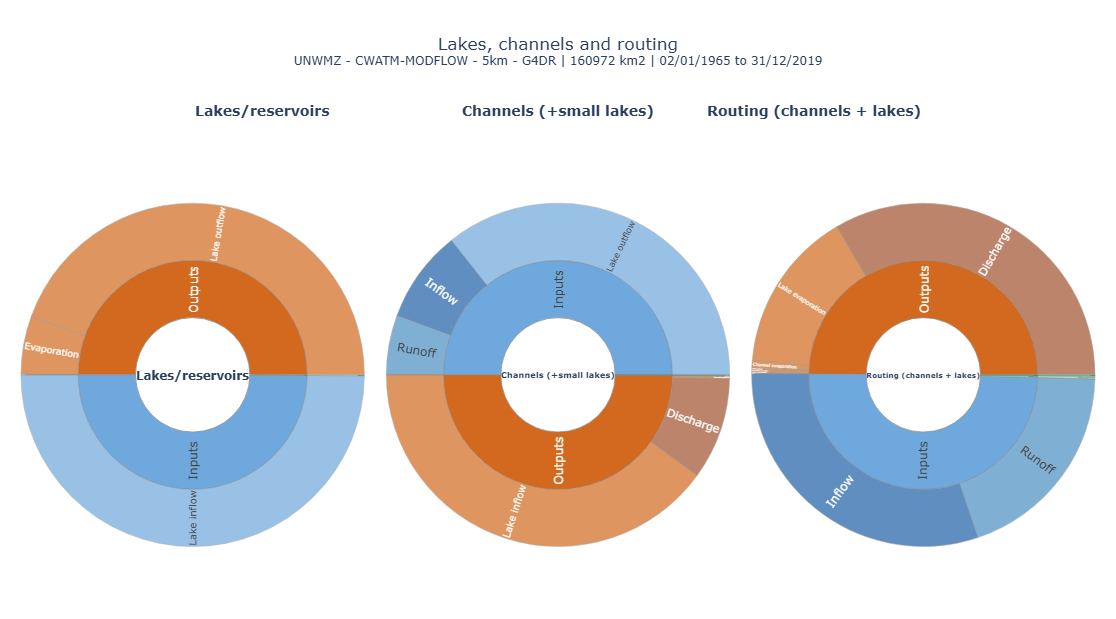

In [42]:
# cell no 19: Lakes/reservoirs, Channels (+small lakes) and Routing (channels + lakes) next to each other
names = [n for n in ["Lakes/reservoirs", "Channels (+small lakes)", "Routing (channels + lakes)"] if n in parts]
print("not drawn (see the 2nd list of cell no 07):", ", ".join(n for n in ["Lakes/reservoirs", "Channels (+small lakes)",
                                                                            "Routing (channels + lakes)"] if n not in parts) or "-")
if names:
    side_by_side([sunburst(n, part_terms(parts[n]), store=False) for n in names], "Lakes, channels and routing").show()

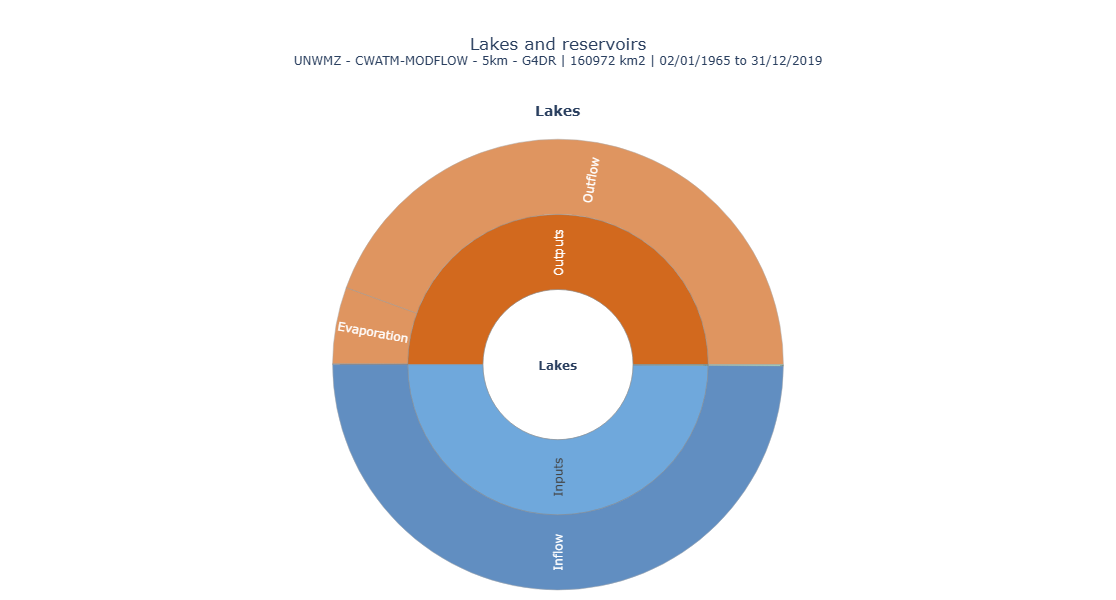

In [43]:
# cell no 20: lakes and reservoirs separately next to each other (WaterBalance csv)
names = [n for n in ["Lakes", "Reservoirs"] if n in parts]
if names:
    side_by_side([sunburst(n, part_terms(parts[n]), store=False) for n in names], "Lakes and reservoirs").show()
else:
    print("lakes / reservoirs separately: includeWaterBodies off or not in this csv (WaterCycle csv: use WaterBalance)")

withdrawal 135.427 mm, sum source x sector 135.427 mm, difference -0.0000 mm
             Irrigation  Domestic  Industry  Livestock
Lake              0.045     1.666     0.071      0.030
Reservoir         0.000     0.000     0.000      0.000
Channel          22.154    21.048     8.098      0.468
Groundwater       9.508    67.449     4.593      0.297


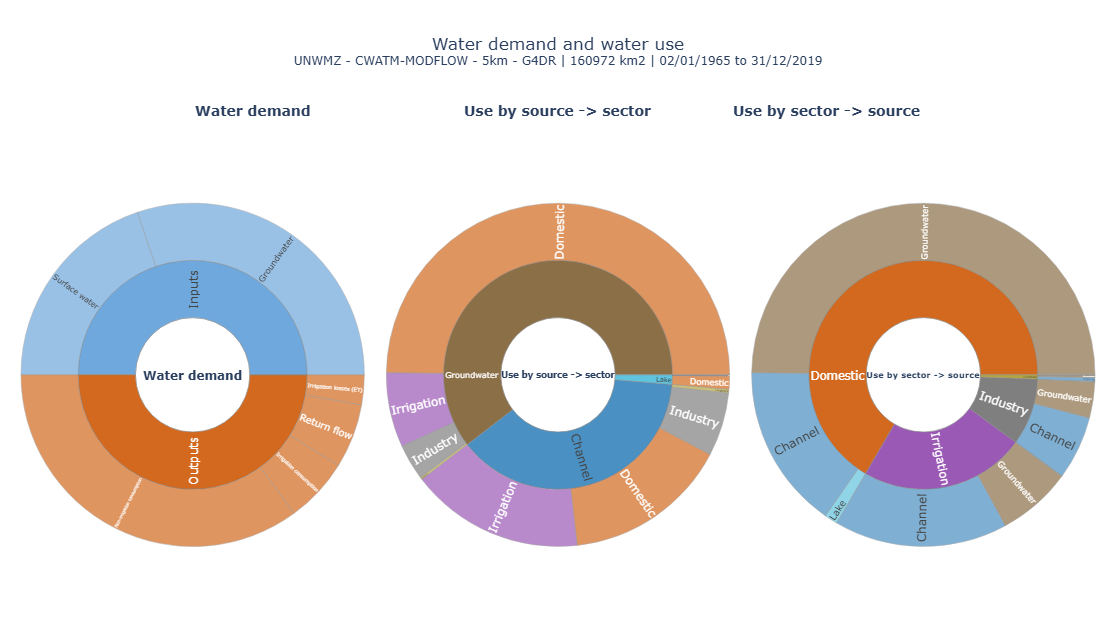

In [44]:
# cell no 21: Water demand (balance) and water use by source x sector (sectorSourceAbstractionFractions)
# source -> sector and sector -> source next to each other
if "Water demand" not in parts:
    print("Water demand: not drawn (see the 2nd list of cell no 07)")
else:
    flist = [sunburst("Water demand", part_terms(parts["Water demand"]), store=False)]
    if use:
        SRCCOL = {"Lake": "#60C4DE", "Reservoir": "#1f5fa8", "Channel": "#4a90c2", "Groundwater": "#8b6f47",
                  "Desalination": "#2ca02c", "Lift area": "#17becf", "Wastewater reuse": "#8c564b",
                  "Irrigation": "#9b59b6", "Domestic": "#d2691e", "Industry": "#7f7f7f", "Livestock": "#b5a642"}
        srcs = list(dict.fromkeys(src for src, _ in use))
        flist.append(composition("Use by source -> sector", {src: [(sec, use.get((src, sec), 0.)) for sec in SECTORS] for src in srcs},
                                 SRCCOL, unit_total=f"withdrawal {withdrawal:.2f} mm"))
        flist.append(composition("Use by sector -> source", {sec: [(src, use.get((src, sec), 0.)) for src in srcs] for sec in SECTORS},
                                 SRCCOL, unit_total=f"withdrawal {withdrawal:.2f} mm"))
        print(f"withdrawal {withdrawal:.3f} mm, sum source x sector {sum(use.values()):.3f} mm, "
              f"difference {withdrawal - sum(use.values()):+.4f} mm")
        print(pd.DataFrame({sec: {src: use.get((src, sec), 0.) for src in srcs} for sec in SECTORS}).round(3).to_string())
    else:
        print("source x sector: sectorSourceAbstractionFractions off -> not drawn")
    side_by_side(flist, "Water demand and water use").show()

unmetDemand: not supplied (limitAbstraction = True)


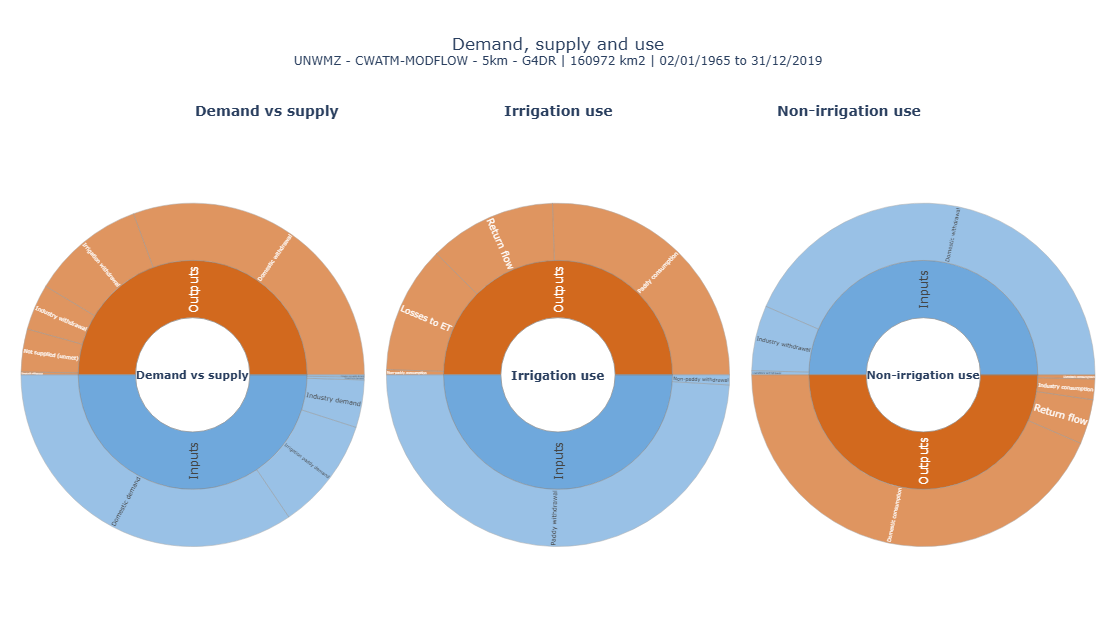

In [45]:
# cell no 22: demand vs supply, irrigation use and non-irrigation use next to each other (WaterBalance csv)
if DEMANDPARTS:
    print("unmetDemand:", "not supplied (limitAbstraction = True)" if opts.get("limitAbstraction", False)
          else "fossil groundwater, part of the withdrawal (limitAbstraction = False) -> demand = withdrawal")
    side_by_side([sunburst(n, part_terms(parts[n]), store=False) for n in DEMANDPARTS], "Demand, supply and use").show()
else:
    print("demand vs supply: includeWaterDemand off or not in this csv (WaterCycle csv: use WaterBalance)")

In [46]:
# cell no 23: all terms of all circles as table [mm and mm/year] and all sunbursts in one html file
tab = []
for name, p in parts.items():
    for side, l, v in part_terms(p):
        tab.append([name, {"In": "In", "Out": "Out", "S+": "Storage into", "S-": "Storage out"}[side], l, v, v / nyears])
for name, groups in compos.items():
    for grp, lst in groups.items():
        for l, v in lst:
            tab.append([name, grp, l, v, v / nyears])
tab = pd.DataFrame(tab, columns=["part", "side", "term", "mm", "mm/year"])
tab.to_csv("watercycle_subparts_terms.csv", index=False)
with open(html_out, "w", encoding="utf-8") as f:
    f.write(f"<html><head><meta charset='utf-8'><title>Water cycle</title></head><body>"
            f"<h2>{title} | station {station} lon {lon:.4f} lat {lat:.4f} | {period}</h2>")
    for i, fig in enumerate(figs.values()):
        f.write(fig.to_html(full_html=False, include_plotlyjs="cdn" if i == 0 else False))
    f.write("</body></html>")
# all figures and tables as json (e.g. for a Claude artifact)
import json
json_out = os.path.splitext(html_out)[0] + ".json"
with open(json_out, "w", encoding="utf-8") as f:
    json.dump(dict(basin=basin, title=title, station=int(station), lon=float(lon), lat=float(lat), area_km2=area / 1e6,
                   period=period, nyears=nyears, tol=tol,
                   summary=json.loads(summary.reset_index().to_json(orient="records")),
                   others=json.loads(others.reset_index().to_json(orient="records")),
                   figures={k: json.loads(fig.to_json()) for k, fig in figs.items()}), f)
print("written:", html_out, json_out, "and watercycle_subparts_terms.csv")
tab.pivot_table(index=["part", "side", "term"], values="mm/year", sort=False).round(2)

written: watercycle_uganda.html watercycle_uganda.json and watercycle_subparts_terms.csv


mm/year
part                    side      term                                      
Total                   In        Rain                               1218.82
                                  Snow                                  0.00
                                  Inflow                              203.93
                        Out       Lateral groundwater flow (neg.)       0.04
                                  Recharge moved by the grid (neg.)     0.78
...                                                                      ...
Use by sector -> source Industry  Groundwater                           0.08
                        Livestock Lake                                  0.00
                                  Reservoir                             0.00
                                  Channel                               0.01
                                  Groundwater                           0.01

[253 rows x 1 columns]